# Dự đoán thời gian sửa chữa theo kỹ thuật viên (KTV): xây dựng, chọn và đóng gói mô hình

**Bài toán.** Học có giám sát, dạng **hồi quy**. Với một phiếu sửa chữa tại thời điểm tiếp nhận $t_0$, dự đoán thời gian thi công thuần $\hat y$ (phút) nếu giao cho một KTV cụ thể, để (a) tính giờ hoàn thành dự kiến (ETA) và (b) gợi ý KTV xong sớm nhất.

$$\hat y = f_\theta(\mathbf x),\qquad \mathbf x=(\text{thiết bị},\ \text{KTV},\ \text{tập mã lỗi},\ \text{số dịch vụ},\ \text{định mức catalog})$$

**Nhãn.** $y=(t_{\text{hoàn thành}}-t_{\text{bắt đầu}})-\sum(\text{thời gian chờ linh kiện / chờ khách duyệt})$. Thời gian chờ không phản ánh tay nghề nên bị trừ.

**Nguyên tắc xuyên suốt của notebook** (mỗi nguyên tắc ứng với một lỗi hay gặp):

| Nguyên tắc | Cách thực hiện | Bước |
|---|---|---|
| Chỉ dùng thông tin biết tại $t_0$ | bảng chính sách cột + `assert` danh sách cột cấm | 4 |
| Tập test độc lập, chạm đúng một lần | tách theo phiếu **trước** mọi phân tích; EDA chỉ trên train | 5, 6, 14 |
| Bộ mã hóa đặc trưng không rò rỉ | `Pipeline` nên bộ mã hóa được fit lại **trong từng fold** | 7, 11 |
| Ước lượng hiệu năng không lạc quan | **nested cross-validation** (tinh chỉnh nằm trong vòng trong) | 11 |
| Mốc so sánh công bằng | 5 baseline từ ngây thơ đến mạnh; baseline mạnh nhất chọn **bằng CV**, không bằng test | 10, 12 |
| Không phóng đại khác biệt | sai số chuẩn (SE), kiểm định Wilcoxon + Bonferroni, bootstrap CI | 12, 14 |
| Khoảng dự báo có bảo đảm | conformal split trên phần dư out-of-fold | 17 |

**Thứ tự các bước:** 1 Môi trường → 2 Nạp dữ liệu → 3 Làm sạch → 4 Thời điểm dự báo & chống rò rỉ → 5 Tách train/test → 6 EDA (chỉ train) → 7 Đặc trưng → 8 Chỉ số → 9 Cross-validation → 10 Baseline & trần nhiễu → 11 Ứng viên & nested CV → 12 Bảng xếp hạng → 13 Ablation augmentation → 14 Đánh giá cuối trên test → 15 Đường cong học → 16 Giải thích mô hình → 17 Khoảng dự báo → 18 Đóng gói bundle → 19 Tổng kết.

## Bước 1. Thiết lập môi trường

Nạp thư viện, cố định `random_state` (kết quả tái lập được) và dùng **chung** `config/` và `src/` với script và API: đặc trưng lúc huấn luyện và lúc dự đoán chỉ được định nghĩa ở một nơi nên không bị lệch nhau (train/serve skew). XGBoost, LightGBM, CatBoost chỉ tham gia cuộc so sánh nếu đã cài.

In [1]:
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit, learning_curve

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from config.config import (ABLATION_REPEATS, AUGMENT_FACTOR, BUNDLE_PATH, CAT_COLS, CV_FOLDS, FEATURE_COLS, GROUP_COL,
                           INNER_CV_FOLDS, INTERVAL_COVERAGE, ISSUE_COL, MAX_PLAUSIBLE_MINUTES, MIN_PREDICTED_MINUTES,
                           NUM_COLS, QUICK_MODE, RANDOM_STATE, RAW_DATA_PATH, REPORTS_DIR, SPLIT_MODE, SYNTHETIC_DATA,
                           TARGET_COL, TEST_SIZE, TICKET_CODE_PREFIX)
from src.augment import augment_repair_dataset
from src.bundle import base_versions, fit_final_pipeline, new_version_tag, package_bundle, reload_check
from src.evaluation import (BASELINE_NAMES, baseline_predictions, bootstrap_mae_ci, bootstrap_mean_ci, calibrate_interval,
                            interval_bounds, paired_wilcoxon, regression_report, technician_effect_test, twin_covered_mask, twin_noise_floor)
from src.features import CATALOG_COL, SERVICES_COL, RepairFeatureBuilder, clean_training_data, issue_key, parse_issue_ids
from src.features import source_patterns
from src.modeling import (build_pipeline, cv_baselines, fit_deployable, leaderboard_row, make_candidates,
                          make_group_folds, n_configs, nested_cv, split_train_test)

warnings.filterwarnings("ignore")
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BEST_COLOR, MODEL_COLOR, BASE_COLOR = "#c0392b", "#2b6cb0", "#9aa5b1"


def savefig(fig, name):
    fig.savefig(REPORTS_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print({k: v for k, v in base_versions().items() if k in ("xgboost", "lightgbm", "catboost")})
print(f"SPLIT_MODE={SPLIT_MODE} | TEST_SIZE={TEST_SIZE} | CV_FOLDS={CV_FOLDS} (outer) x {INNER_CV_FOLDS} (inner) | SEED={RANDOM_STATE}")
if QUICK_MODE:
    print("CẢNH BÁO: QUICK_MODE=True (lưới rút gọn). Chỉ để chạy thử; đặt False trong config/config.py cho kết quả báo cáo.")

Python 3.13.5 | pandas 2.2.3 | scikit-learn 1.6.1
{'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'catboost': '1.2.10'}
SPLIT_MODE=group | TEST_SIZE=0.2 | CV_FOLDS=5 (outer) x 3 (inner) | SEED=42


## Bước 2. Nạp dữ liệu thô

Đọc dữ liệu do `scripts/01_extract_raw_data.py` xuất từ MySQL (mỗi phiếu hoàn tất = 1 dòng) và kiểm tra hình dạng, kiểu dữ liệu, giá trị thiếu.

$$D_{\text{raw}}=\{(\mathbf x_i,y_i)\}_{i=1}^{N},\qquad y_i\in\mathbb R_{>0}$$

**Lưu ý trung thực.** Nếu `SYNTHETIC_DATA = True` thì dữ liệu do script seed sinh theo quy luật nghiệp vụ. Khi đó mọi con số đo **độ khớp với quy luật mô phỏng**, chưa phải hiệu năng vận hành thật. Quy trình chứng minh được; hiệu năng thực địa phải chờ dữ liệu thật.

In [2]:
if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(f"Chưa có {RAW_DATA_PATH}. Hãy chạy: python scripts/01_extract_raw_data.py")
df_raw = pd.read_csv(RAW_DATA_PATH)
need = set(FEATURE_COLS) | {TARGET_COL, GROUP_COL, "is_reassigned"}
assert need <= set(df_raw.columns), f"CSV thiếu cột: {sorted(need - set(df_raw.columns))}"
print(f"Dữ liệu thô: {df_raw.shape[0]} dòng x {df_raw.shape[1]} cột | SYNTHETIC_DATA = {SYNTHETIC_DATA}")
patterns = source_patterns(df_raw)
display(patterns.to_frame("số phiếu").rename_axis("dạng mã phiếu"))
if len(patterns) > 1:
    print(f"CẢNH BÁO: có {len(patterns)} dạng mã phiếu = dữ liệu đến từ nhiều nguồn/đợt sinh. "
          f"Bước 3 chỉ giữ phiếu có mã bắt đầu bằng {TICKET_CODE_PREFIX!r} (TICKET_CODE_PREFIX trong config).")
display(pd.DataFrame({"kiểu": df_raw.dtypes.astype(str), "thiếu": df_raw.isna().sum(), "số giá trị khác nhau": df_raw.nunique()}).T)

Dữ liệu thô: 1236 dòng x 22 cột | SYNTHETIC_DATA = True


,số phiếu
dạng mã phiếu,
ST-SEED-#,1236


,ticket_id,ticket_code,branch_id,device_model_id,device_model_name,total_services_count,service_issue_ids_list,service_issue_names_list,service_type_codes_list,total_catalog_standard_duration_minutes,...,technician_name,is_reassigned,count_waiting_part_events,count_waiting_approval_events,total_pause_events_count,total_pause_duration_minutes,actual_repair_started_at,actual_repair_completed_at,actual_repair_duration_minutes,net_repair_duration_minutes
kiểu,int64,object,int64,int64,object,int64,object,object,object,float64,...,object,int64,float64,float64,int64,float64,object,object,int64,float64
thiếu,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
số giá trị khác nhau,1156,1156,1,21,21,3,60,60,4,12,...,3,2,2,2,2,32,1039,1123,144,136


## Bước 3. Làm sạch dữ liệu

Chỉ giữ các dòng mà nhãn **có nghĩa và độc lập**. Hàm `clean_training_data` áp sáu luật (mỗi luật đếm số dòng nó loại):

| Luật | Lý do |
|---|---|
| Loại phiếu không thuộc nguồn dữ liệu đã mô tả (`TICKET_CODE_PREFIX`) | **một nguồn, một quy luật sinh**: trộn nhiều đợt sinh có hệ số khác nhau làm nhãn học sai và làm sai mọi kiểm định |
| Loại phiếu chuyển giao KTV (`is_reassigned ≠ 0`) | thời gian là của nhiều người, nhãn không thuộc một KTV |
| Loại nhãn $y\le0$ hoặc không có dịch vụ | nhãn vô nghĩa |
| Loại phiếu thiếu KTV | không thể dự đoán "theo KTV" |
| Loại nhãn $>$ `MAX_PLAUSIBLE_MINUTES` (8 giờ) | nhập liệu lỗi (quên đóng phiếu); **không** cắt ngoại lai thông thường |
| Mỗi phiếu đúng một dòng | một phiếu ở cả train và test là rò rỉ |

Làm sạch xong có `assert` làm hậu điều kiện: sai thì dừng, không đi tiếp trên dữ liệu bẩn.

In [3]:
df, clean_report = clean_training_data(df_raw, TARGET_COL, GROUP_COL, MAX_PLAUSIBLE_MINUTES, TICKET_CODE_PREFIX)
summary = pd.DataFrame([
    ("Dữ liệu thô", clean_report["rows_raw"]),
    ("  loại: phiếu nguồn khác (mã không khớp TICKET_CODE_PREFIX)", clean_report["dropped_other_source"]),
    ("  loại: phiếu chuyển giao KTV", clean_report["dropped_reassigned"]),
    ("  loại: nhãn <= 0 hoặc không có dịch vụ", clean_report["dropped_invalid_target_or_no_service"]),
    ("  loại: thiếu KTV", clean_report["dropped_missing_technician"]),
    ("  loại: nhãn phi thực tế (> 8 giờ)", clean_report["dropped_implausible_duration"]),
    ("  loại: phiếu trùng", clean_report["dropped_duplicate_tickets"]),
    ("Dữ liệu sạch", clean_report["rows_clean"]),
], columns=["Bước", "Số dòng"])
display(summary)
if TICKET_CODE_PREFIX:
    assert df["ticket_code"].astype(str).str.startswith(TICKET_CODE_PREFIX).all(), "Còn phiếu khác nguồn"
    assert source_patterns(df).shape[0] == 1, "Còn nhiều dạng mã phiếu"
assert df[GROUP_COL].is_unique and (df["is_reassigned"] == 0).all()
assert (df[TARGET_COL] > 0).all() and (df[SERVICES_COL] > 0).all() and df["technician_id"].notna().all()
print(f"{len(df)} phiếu | {df['technician_id'].nunique()} KTV | {df['device_model_id'].nunique()} đời máy | "
      f"{df[ISSUE_COL].map(issue_key).nunique()} tổ hợp mã lỗi")

,Bước,Số dòng
0,Dữ liệu thô,1236
1,loại: phiếu nguồn khác (mã không khớp TICKET...,0
2,loại: phiếu chuyển giao KTV,160
3,loại: nhãn <= 0 hoặc không có dịch vụ,0
4,loại: thiếu KTV,0
5,loại: nhãn phi thực tế (> 8 giờ),0
6,loại: phiếu trùng,0
7,Dữ liệu sạch,1076


1076 phiếu | 3 KTV | 21 đời máy | 57 tổ hợp mã lỗi


## Bước 4. Thời điểm dự báo $t_0$ và chống rò rỉ dữ liệu

**Quy tắc:** chỉ cho mô hình thấy những gì hệ thống **biết được tại $t_0$** (lúc tiếp nhận và lập hạng mục). Đặc trưng chỉ có sau khi sửa xong làm mô hình "gian lận" lúc huấn luyện và vô dụng lúc chạy thật (rò rỉ tương lai).

$$\mathbf x_i\subseteq\mathcal I(t_0),\qquad y_i\notin\mathcal I(t_0)$$

In [4]:
FORBIDDEN = {"actual_repair_duration_minutes", "total_pause_duration_minutes", "total_pause_events_count",
             "count_waiting_part_events", "count_waiting_approval_events", "actual_repair_started_at",
             "actual_repair_completed_at", "is_reassigned", "total_parts_quantity_used", TARGET_COL, GROUP_COL}
assert not (set(FEATURE_COLS) & FORBIDDEN), "Có đặc trưng rò rỉ trong FEATURE_COLS!"

policy = pd.DataFrame([
    ("device_model_id", "khi tiếp nhận", "DÙNG"),
    ("technician_id", "khi phân công (hoặc thử từng ứng viên)", "DÙNG"),
    ("service_issue_ids_list, total_services_count, total_catalog_standard_duration_minutes", "khi lập hạng mục sửa chữa", "DÙNG"),
    ("branch_id", "hằng số (1 chi nhánh)", "BỎ: không mang thông tin"),
    ("total_parts_quantity_used", "chỉ biết sau khi xuất kho", "BỎ: lệch train/serve"),
    ("actual_repair_*, total_pause_*, count_waiting_*", "chỉ biết sau khi sửa", "BỎ: rò rỉ tương lai"),
    ("is_reassigned", "chỉ biết sau khi sửa", "BỎ: đã lọc ở Bước 3"),
    ("ticket_id, ticket_code, tên", "định danh / văn bản", "BỎ: không phải đặc trưng (ticket_id chỉ làm nhóm chia fold)"),
], columns=["Cột", "Thời điểm biết", "Quyết định"])
display(policy)
print("Đặc trưng đầu vào (5 thuộc tính gốc):", FEATURE_COLS)

,Cột,Thời điểm biết,Quyết định
0,device_model_id,khi tiếp nhận,DÙNG
1,technician_id,khi phân công (hoặc thử từng ứng viên),DÙNG
2,"service_issue_ids_list, total_services_count, ...",khi lập hạng mục sửa chữa,DÙNG
3,branch_id,hằng số (1 chi nhánh),BỎ: không mang thông tin
4,total_parts_quantity_used,chỉ biết sau khi xuất kho,BỎ: lệch train/serve
5,"actual_repair_*, total_pause_*, count_waiting_*",chỉ biết sau khi sửa,BỎ: rò rỉ tương lai
6,is_reassigned,chỉ biết sau khi sửa,BỎ: đã lọc ở Bước 3
7,"ticket_id, ticket_code, tên",định danh / văn bản,BỎ: không phải đặc trưng (ticket_id chỉ làm nh...


Đặc trưng đầu vào (5 thuộc tính gốc): ['total_services_count', 'total_catalog_standard_duration_minutes', 'device_model_id', 'technician_id', 'service_issue_ids_list']


## Bước 5. Tách train/test theo phiếu

Tạo tập test độc lập thật sự, đóng vai "phiếu tương lai", **chỉ dùng một lần ở Bước 14**. Mọi bước học và phân tích (EDA, mã hóa, tinh chỉnh, chọn mô hình) chỉ được thấy train.

$$D=D_{\text{train}}\cup D_{\text{test}},\qquad \text{tickets}(D_{\text{train}})\cap\text{tickets}(D_{\text{test}})=\emptyset$$

`SPLIT_MODE="group"`: ngẫu nhiên theo `ticket_id`. `SPLIT_MODE="time"`: 20% phiếu mới nhất làm test (mô phỏng đúng việc dự đoán tương lai; nên dùng khi có dữ liệu thật theo thời gian).

In [5]:
train_df, test_df = split_train_test(df)
assert set(train_df[GROUP_COL]).isdisjoint(test_df[GROUP_COL]), "Rò rỉ: có phiếu ở cả train và test"
y_tr = train_df[TARGET_COL].to_numpy(float)
y_te = test_df[TARGET_COL].to_numpy(float)
print(f"train = {len(train_df)} phiếu | test = {len(test_df)} phiếu ({len(test_df)/len(df):.0%}) | chế độ: {SPLIT_MODE}")

# Test có đại diện cho train không? (nếu quá khác thì điểm test không công bằng)
ks = stats.ks_2samp(y_tr, y_te)
ct = pd.crosstab(pd.concat([train_df["technician_id"], test_df["technician_id"]]),
                 np.r_[np.zeros(len(train_df)), np.ones(len(test_df))])
chi_p = stats.chi2_contingency(ct)[1]
print(f"Phân phối nhãn train vs test: KS p = {ks.pvalue:.3f} | tỉ lệ KTV train vs test: chi-square p = {chi_p:.3f}")
print("=> p > 0.05: không có bằng chứng hai tập khác nhau." if min(ks.pvalue, chi_p) > 0.05
      else "=> p <= 0.05: hai tập khác nhau về phân phối; cân nhắc khi đọc điểm test (nếu SPLIT_MODE='time' thì đây là hiện tượng thật).")

train = 860 phiếu | test = 216 phiếu (20%) | chế độ: group
Phân phối nhãn train vs test: KS p = 0.347 | tỉ lệ KTV train vs test: chi-square p = 0.573
=> p > 0.05: không có bằng chứng hai tập khác nhau.


## Bước 6. Phân tích khám phá (EDA) và kiểm định, **chỉ trên tập train**

Mỗi phân tích trả lời một câu hỏi ảnh hưởng đến thiết kế phía sau:

1. **Nhãn phân bố thế nào?** (độ lệch $g_1$) → chọn KPI và kiểu khoảng dự báo.
2. **Định mức catalog đã dự đoán tốt tới đâu?** (Pearson $r$) → nếu đã tốt, ML chỉ cần phần dư.
3. **KTV có thật sự khác nhau về tốc độ không?** Tỉ lệ hiệu suất $\rho_i=y_i/\text{catalog}_i$ ($\rho=1$ là đúng định mức). Kiểm định hai lớp:
   * **ANOVA / Kruskal–Wallis** trên $\rho$ của ca 1 dịch vụ (thô; Kruskal không giả định phân phối chuẩn).
   * **ANCOVA (F-test từng phần)** trên $\log y$ sau khi hiệu chỉnh độ khó ca (log catalog, số dịch vụ, mã lỗi, thiết bị). Cần thiết vì KTV **không được giao ca ngẫu nhiên**: nếu KTV nhanh toàn nhận ca dễ thì ANOVA thô sẽ nhầm "ca dễ" thành "KTV giỏi".

$$F=\frac{SS_B/(k-1)}{SS_W/(N-k)},\qquad F_{\text{partial}}=\frac{(RSS_0-RSS_1)/\Delta df}{RSS_1/df_1},\qquad \eta^2_{\text{partial}}=\frac{RSS_0-RSS_1}{RSS_0}$$

Nếu không có tín hiệu KTV thì việc "dự đoán theo KTV" không có cơ sở và phải sửa nguồn dữ liệu.

Nhãn y: n=860 | trung bình=58.7 | trung vị=49.0 | độ lệch chuẩn=29.9 | P5-P95=[27, 113] | độ lệch g1=2.17
Pearson(định mức, nhãn) r = 0.902
Ca 1 dịch vụ (n=554): ANOVA F=106.5, p=8.01e-40, eta^2=0.279 | Kruskal-Wallis p=1.73e-33
ANCOVA có hiệu chỉnh độ khó ca (toàn train): F=133.5, p=5.76e-51, partial eta^2=0.244
=> CÓ tín hiệu KTV sau khi hiệu chỉnh độ khó ca.


,số ca 1 dịch vụ,rho trung bình (thô),hệ số tốc độ (đã hiệu chỉnh)
5343,251,0.912,0.891
5344,195,1.005,1.003
5345,108,1.151,1.118


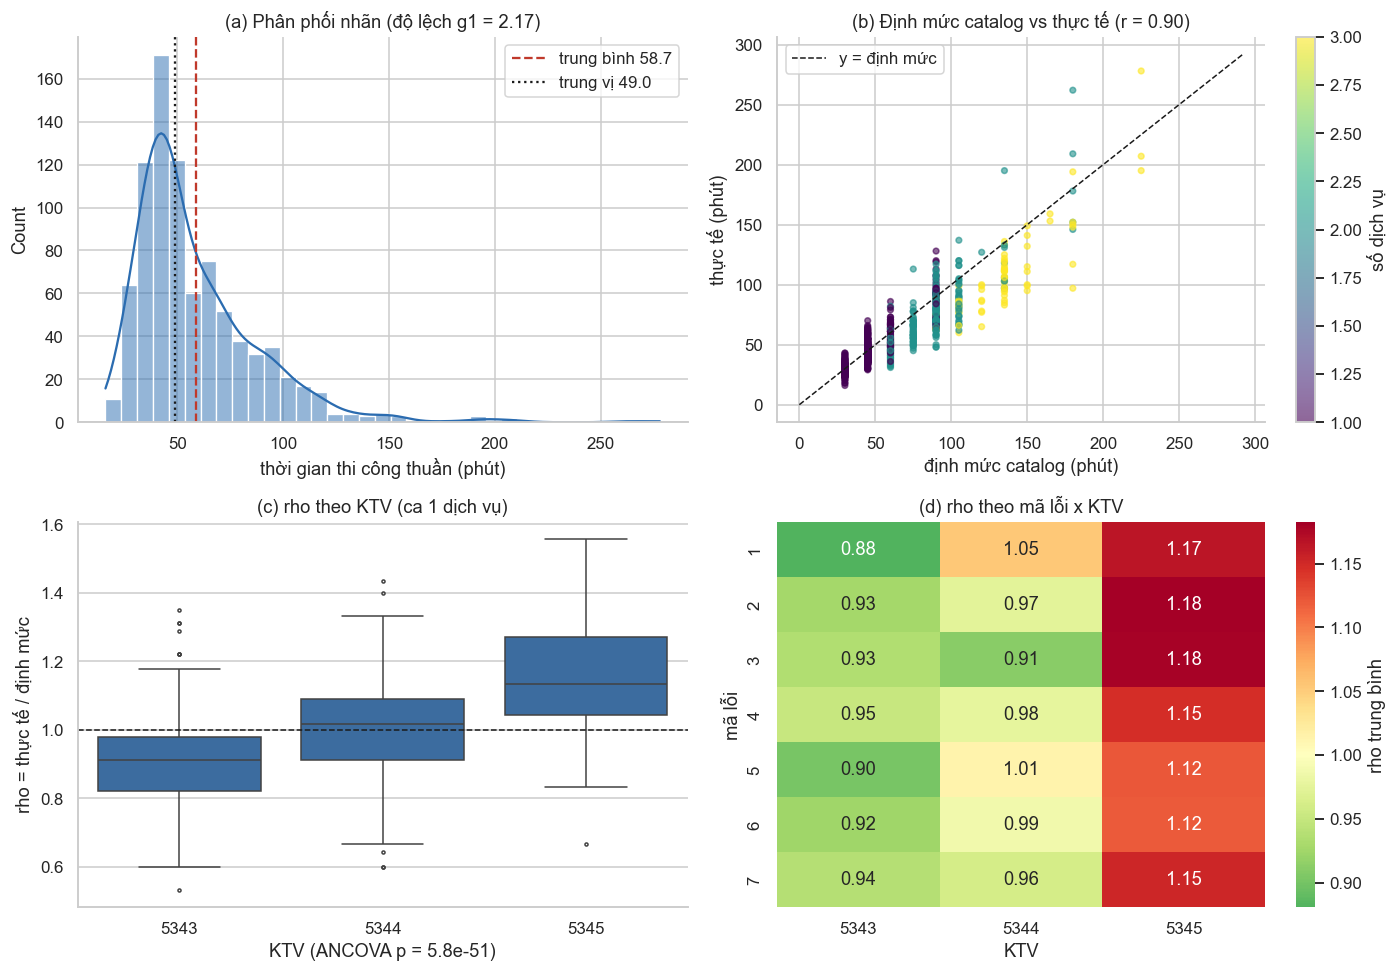

In [6]:
eda = train_df.copy()
eda["ratio"] = eda[TARGET_COL] / eda[CATALOG_COL]
single = eda[eda[SERVICES_COL] == 1].copy()

# --- thống kê mô tả và kiểm định
g1 = stats.skew(y_tr)
r_cat = np.corrcoef(eda[CATALOG_COL], y_tr)[0, 1]
groups = [g["ratio"].to_numpy() for _, g in single.groupby("technician_id") if len(g) > 1]
anova = stats.f_oneway(*groups)
kw = stats.kruskal(*groups)
ss_tot = ((single["ratio"] - single["ratio"].mean()) ** 2).sum()
ss_b = sum(len(g) * (g.mean() - single["ratio"].mean()) ** 2 for g in groups)
anc = technician_effect_test(train_df, TARGET_COL, ISSUE_COL)

print(f"Nhãn y: n={len(y_tr)} | trung bình={y_tr.mean():.1f} | trung vị={np.median(y_tr):.1f} | độ lệch chuẩn={y_tr.std(ddof=1):.1f} | "
      f"P5-P95=[{np.percentile(y_tr,5):.0f}, {np.percentile(y_tr,95):.0f}] | độ lệch g1={g1:.2f}")
print(f"Pearson(định mức, nhãn) r = {r_cat:.3f}")
print(f"Ca 1 dịch vụ (n={len(single)}): ANOVA F={anova.statistic:.1f}, p={anova.pvalue:.2e}, eta^2={ss_b/ss_tot:.3f} | Kruskal-Wallis p={kw.pvalue:.2e}")
print(f"ANCOVA có hiệu chỉnh độ khó ca (toàn train): F={anc['F']:.1f}, p={anc['p_value']:.2e}, partial eta^2={anc['partial_eta2']:.3f}")
verdict_tech = anc["p_value"] < 0.05
print("=> CÓ tín hiệu KTV sau khi hiệu chỉnh độ khó ca." if verdict_tech else
      "=> KHÔNG có bằng chứng KTV khác nhau sau hiệu chỉnh: dự đoán theo KTV chưa có cơ sở, kiểm tra nguồn dữ liệu.")

raw_idx = single.groupby("technician_id")["ratio"].mean()
tech_table = pd.DataFrame({"số ca 1 dịch vụ": single.groupby("technician_id").size(),
                           "rho trung bình (thô)": raw_idx.round(3),
                           "hệ số tốc độ (đã hiệu chỉnh)": pd.Series(anc["factors"]).round(3)})
display(tech_table)

# --- Hình 1: bốn câu hỏi EDA trong một hình
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(y_tr, bins=35, kde=True, ax=ax[0, 0], color=MODEL_COLOR)
ax[0, 0].axvline(y_tr.mean(), ls="--", c=BEST_COLOR, label=f"trung bình {y_tr.mean():.1f}")
ax[0, 0].axvline(np.median(y_tr), ls=":", c="k", label=f"trung vị {np.median(y_tr):.1f}")
ax[0, 0].set(title=f"(a) Phân phối nhãn (độ lệch g1 = {g1:.2f})", xlabel="thời gian thi công thuần (phút)")
ax[0, 0].legend()

sc = ax[0, 1].scatter(eda[CATALOG_COL], y_tr, c=eda[SERVICES_COL], cmap="viridis", s=14, alpha=0.6)
lim = [0, max(eda[CATALOG_COL].max(), y_tr.max()) * 1.05]
ax[0, 1].plot(lim, lim, "k--", lw=1, label="y = định mức")
ax[0, 1].set(title=f"(b) Định mức catalog vs thực tế (r = {r_cat:.2f})", xlabel="định mức catalog (phút)", ylabel="thực tế (phút)")
ax[0, 1].legend(); plt.colorbar(sc, ax=ax[0, 1], label="số dịch vụ")

sns.boxplot(data=single, x="technician_id", y="ratio", ax=ax[1, 0], color=MODEL_COLOR, fliersize=2)
ax[1, 0].axhline(1.0, ls="--", c="k", lw=1)
ax[1, 0].set(title="(c) rho theo KTV (ca 1 dịch vụ)", xlabel=f"KTV (ANCOVA p = {anc['p_value']:.1e})", ylabel="rho = thực tế / định mức")

single["issue_one"] = single[ISSUE_COL].map(lambda v: (parse_issue_ids(v) or [0])[0])
heat = single.pivot_table(index="issue_one", columns="technician_id", values="ratio", aggfunc="mean")
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdYlGn_r", center=1.0, ax=ax[1, 1], cbar_kws={"label": "rho trung bình"})
ax[1, 1].set(title="(d) rho theo mã lỗi x KTV", xlabel="KTV", ylabel="mã lỗi")
plt.tight_layout(); savefig(fig, "01_eda"); plt.show()

**Cách đọc Hình 1.** (a) Đuôi phải dài ($g_1>0$): dùng **MAE** làm KPI chính (ít bị ca ngoại lai kéo lệch) và nên thử hàm mất mát tuyệt đối. (b) Định mức tương quan mạnh với thực tế nên là đặc trưng số một; độ phân tán dọc quanh mỗi mức định mức là phần ML cần giải thích, và phần không giải thích được là nhiễu. (c, d) Nếu mỗi KTV nhanh/chậm **đều** trên mọi mã lỗi thì thời gian $\approx$ định mức $\times$ hệ số KTV, một cấu trúc **nhân**. Cấu trúc này giải thích hai thiết kế phía sau: mô hình *Ridge log-nhân* ở Bước 11 và khoảng dự báo *tỉ lệ* ở Bước 17. Nếu dữ liệu là mô phỏng thì độ đều tăm tắp ở (d) là dấu hiệu của chính quy luật sinh dữ liệu.

## Bước 7. Xây dựng đặc trưng

`RepairFeatureBuilder` biến bảng thô thành ma trận số $\mathbf X\in\mathbb R^{N\times d}$ và **chỉ fit trên dữ liệu train**; phiếu lạ cho toàn số 0 thay vì báo lỗi (và `unknown_values` cảnh báo).

1. Tỉ lệ nghiệp vụ và log (cây khó tự tạo phép chia; mô hình nhân cần log): $x_{\text{dur/svc}}=\dfrac{\text{catalog}}{\text{số dịch vụ}}$, $\ x_{\log}=\log(1+\text{catalog})$.
2. **Multi-hot** cho tập mã lỗi $\mathcal S_i$ (một phiếu có thể nhiều lỗi): $v_{i,k}=\mathbb 1[k\in\mathcal S_i]$.
3. **One-hot** cho ID thiết bị và ID KTV. ID là nhãn danh định (KTV 5345 không "lớn hơn" KTV 5343): $u_{i,c}=\mathbb 1[\text{id}_i=c]$.

Hai chế độ: `ohe` (Ridge, Cây, RF, XGBoost, LightGBM) và `native` (CatBoost giữ ID dạng chuỗi và tự mã hóa).

**Chống rò rỉ khi tinh chỉnh:** ở Bước 11, builder nằm **bên trong** `Pipeline`, nên mỗi lần fit trong cross-validation builder được fit lại chỉ trên phần train của fold đó. Ô dưới chỉ minh họa trên toàn train.

In [7]:
builders = {m: RepairFeatureBuilder(NUM_COLS, CAT_COLS, ISSUE_COL, cat_mode=m).fit(train_df[FEATURE_COLS]) for m in ("ohe", "native")}
Xo = builders["ohe"].transform(train_df[FEATURE_COLS])
print(f"ohe   : {Xo.shape[0]} x {Xo.shape[1]} | native: {builders['native'].transform(train_df[FEATURE_COLS]).shape[1]} cột")
print(f"Từ vựng học từ train: mã lỗi {builders['ohe'].issue_vocab_} | {len(builders['ohe'].categories_['device_model_id'])} đời máy | "
      f"KTV {builders['ohe'].categories_['technician_id']}")
display(Xo.head(3))

# Phép thử giá trị lạ: transform vẫn chạy, unknown_values phát hiện đúng
probe = train_df[FEATURE_COLS].iloc[[0]].copy()
probe["technician_id"], probe["device_model_id"] = 999999, 888888
unk = builders["ohe"].unknown_values(probe)
assert set(unk) == {"technician_id", "device_model_id"}
assert builders["ohe"].transform(probe).filter(regex="^(technician_id|device_model_id)__").sum().sum() == 0
print("Giá trị lạ được phát hiện:", unk, "| các cột one-hot tương ứng = 0, không lỗi.")

ohe   : 860 x 35 | native: 13 cột
Từ vựng học từ train: mã lỗi [1, 2, 3, 4, 5, 6, 7] | 21 đời máy | KTV [5343, 5344, 5345]


,total_services_count,total_catalog_standard_duration_minutes,duration_per_service,log_catalog,issue_1,issue_2,issue_3,issue_4,issue_5,issue_6,...,device_model_id__1429,device_model_id__1440,device_model_id__1441,device_model_id__1442,device_model_id__1443,device_model_id__1444,device_model_id__1445,technician_id__5343,technician_id__5344,technician_id__5345
0,3.0,135.0,45.0,4.912655,1.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,2.0,105.0,52.5,4.663439,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
2,1.0,90.0,90.0,4.510860,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Giá trị lạ được phát hiện: {'device_model_id': [888888], 'technician_id': [999999]} | các cột one-hot tương ứng = 0, không lỗi.


## Bước 8. Chỉ số đánh giá và kiểm thử công thức

Với sai số $e_i=\hat y_i-y_i$ (phút):

$$\text{MAE}=\frac1N\sum|e_i|,\quad \text{RMSE}=\sqrt{\frac1N\sum e_i^2},\quad R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2},\quad \text{P90}=Q_{0.9}(|e_i|),\quad \text{within-5}=\frac1N\sum\mathbb 1[|e_i|\le5],\quad \text{bias}=\frac1N\sum e_i$$

* **MAE là KPI chính**: "trung bình lệch bao nhiêu phút", cùng đơn vị với nghiệp vụ, ít bị ngoại lai kéo lệch. RMSE phạt nặng ca lệch lớn. $R^2$ là tỉ lệ biến thiên được giải thích.
* bias dương = đoán dôi, âm = đoán hụt (ảnh hưởng ETA khách thấy).
* **Khoảng tin cậy bootstrap 95% cho MAE:** lấy mẫu có hoàn lại 2000 lần các $|e_i|$. Với tập test vài trăm mẫu, hai MAE hơn kém trong khoảng này chưa chắc khác nhau thật.

Ô dưới kiểm tra hàm đo bằng **tính tay** (bằng chứng mọi con số về sau được tính đúng).

In [8]:
y_mock, p_mock = np.array([30.0, 40.0, 50.0, 60.0]), np.array([33.0, 38.0, 50.0, 66.0])   # e = (3, -2, 0, 6)
m = regression_report(y_mock, p_mock)
hand = {"MAE": 11 / 4, "RMSE": np.sqrt(49 / 4), "R2": 1 - 49 / 500, "bias": 7 / 4, "P90_abs_err": 5.1, "within_5min_pct": 75.0}
for k, v in hand.items():
    assert abs(m[k] - v) < 1e-9, f"{k}: hàm cho {m[k]} nhưng tay tính {v}"
print("Hàm regression_report khớp công thức tính tay:", {k: round(v, 4) for k, v in m.items()})

Hàm regression_report khớp công thức tính tay: {'MAE': 2.75, 'RMSE': 3.5, 'R2': 0.902, 'P90_abs_err': 5.1, 'within_5min_pct': 75.0, 'bias': 1.75}


## Bước 9. Giao thức cross-validation theo nhóm phiếu

Ước lượng hiệu năng để chọn mô hình **mà không chạm vào test**: chia train theo phiếu thành $K=5$ fold; lần lượt học trên 4 fold, kiểm tra trên 1 fold.

$$\text{CV-MAE}=\frac1K\sum_{k=1}^{K}\text{MAE}_k,\qquad s=\sqrt{\tfrac1{K-1}\sum_k(\text{MAE}_k-\text{CV-MAE})^2},\qquad \text{SE}=\frac{s}{\sqrt K}$$

Mọi mô hình và baseline dùng **đúng cùng các fold** ("cùng một đề thi"). Hai mô hình cách nhau ít hơn một SE là hòa thống kê. Hàm `make_group_folds` xáo các phiếu bằng seed cố định rồi chia đều, nên fold không phụ thuộc thứ tự bản ghi trong DB.

In [9]:
outer_folds = make_group_folds(train_df[GROUP_COL], CV_FOLDS, RANDOM_STATE)
seen = np.concatenate([va for _, va in outer_folds])
assert sorted(seen) == list(range(len(train_df))), "Mỗi mẫu phải được kiểm định đúng một lần"
for k, (tr, va) in enumerate(outer_folds, 1):
    assert set(train_df[GROUP_COL].iloc[tr]).isdisjoint(train_df[GROUP_COL].iloc[va])
print(f"{CV_FOLDS} fold | kích thước kiểm định: {[len(va) for _, va in outer_folds]} | không phiếu nào ở cả hai phía của một fold")

5 fold | kích thước kiểm định: [172, 172, 172, 172, 172] | không phiếu nào ở cả hai phía của một fold


## Bước 10. Baseline (mốc phải vượt) và trần nhiễu

Một mô hình ML chỉ đáng dùng nếu thắng được cách làm đơn giản. Năm baseline, mỗi baseline được **học lại trong từng fold**:

| Baseline | Dự đoán | Ý nghĩa |
|---|---|---|
| B0 Trung bình | $\hat y=\bar y_{\text{train}}$ | không dùng thông tin |
| B1 Định mức catalog | $\hat y=\text{catalog}$ | cách hệ thống đang làm |
| B2 Tuyến tính theo catalog | $\hat y=a\cdot\text{catalog}+b$ | hiệu chỉnh tuyến tính định mức |
| B3 Định mức × hệ số KTV | $\hat y=\text{catalog}\times\bar\rho_{\text{KTV}}$ | mô hình **nhân** đơn giản nhất, hệ số học từ dữ liệu |
| B4 Bảng tra | trung bình $y$ của cùng (thiết bị, tổ hợp lỗi, KTV) | "học thuộc" các tổ hợp đã gặp |

**Baseline mạnh nhất được chọn bằng CV** (không bằng test, vì chọn theo test là nhìn trộm). Đó là mốc dùng để báo cáo "giảm bao nhiêu %".

**Trần nhiễu (pure error).** Các phiếu có đặc trưng **giống hệt nhau** chỉ khác nhau ở nhiễu, nên phương sai nội nhóm cho biết sai số bất khả giảm: $\sigma^2=\sum_g(n_g-1)s_g^2/\sum_g(n_g-1)$. Mô hình có sai số thấp hơn rõ rệt trần này là dấu hiệu đáng ngờ (rò rỉ, nhớ vẹt, dữ liệu trùng); mô hình gần trần là đã khai thác hết thông tin có trong đặc trưng.

In [10]:
y_tr = train_df[TARGET_COL].to_numpy(float)
oof_base = cv_baselines(train_df, TARGET_COL, ISSUE_COL, outer_folds, y_tr)
cv_rows = {n: leaderboard_row(n, "baseline", o, y_tr, outer_folds) for n, o in oof_base.items()}
base_tbl = pd.DataFrame(cv_rows.values()).sort_values("cv_mae")[["name", "cv_mae", "cv_se", "cv_rmse", "cv_r2"]].round(3)
display(base_tbl.reset_index(drop=True))

PRIMARY_BASELINE = min(cv_rows, key=lambda n: cv_rows[n]["cv_mae"])
print(f"Baseline mạnh nhất theo CV (mốc so sánh chính): {PRIMARY_BASELINE}  (CV-MAE = {cv_rows[PRIMARY_BASELINE]['cv_mae']:.3f})")

noise = twin_noise_floor(train_df, TARGET_COL, ISSUE_COL)
print(f"Trần nhiễu từ phiếu song sinh: RMSE >= {noise['noise_rmse_floor']:.2f} | MAE xấp xỉ >= {noise['noise_mae_floor']:.2f} "
      f"(ước lượng CHỈ trên {noise['share_covered']:.0%} số phiếu có song sinh, {noise['n_groups_total']} tổ hợp đặc trưng khác nhau)")
print("Lưu ý: tập phiếu có song sinh thường là ca ngắn nên trần này chỉ so sánh công bằng với sai số của mô hình trên CHÍNH tập đó (Bước 12).")

,name,cv_mae,cv_se,cv_rmse,cv_r2
0,B3 Định mức x hệ số KTV,8.568,0.292,12.524,0.825
1,B2 Tuyến tính theo catalog,8.803,0.358,13.017,0.811
2,B1 Định mức catalog,10.844,0.285,15.529,0.731
3,B4 Bảng tra (thiết bị x lỗi x KTV),12.681,0.541,19.941,0.556
4,B0 Trung bình,21.982,0.538,29.956,-0.002


Baseline mạnh nhất theo CV (mốc so sánh chính): B3 Định mức x hệ số KTV  (CV-MAE = 8.568)
Trần nhiễu từ phiếu song sinh: RMSE >= 7.18 | MAE xấp xỉ >= 5.42 (ước lượng CHỈ trên 68% số phiếu có song sinh, 488 tổ hợp đặc trưng khác nhau)
Lưu ý: tập phiếu có song sinh thường là ca ngắn nên trần này chỉ so sánh công bằng với sai số của mô hình trên CHÍNH tập đó (Bước 12).


## Bước 11. Các mô hình ứng viên và nested cross-validation

Đưa các họ thuật toán khác nhau vào cùng một cuộc thi, mỗi họ đại diện một giả định khác nhau:

| Mô hình | Giả định / ý nghĩa |
|---|---|
| Ridge (tuyến tính) | quan hệ **cộng** tuyến tính: $\min_w\sum(y_i-w^\top x_i)^2+\alpha\lVert w\rVert^2$ |
| Ridge (log-nhân) | quan hệ **nhân**: $\log y=w^\top x$ ⇒ $y=\text{catalog}^b\times\text{tốc độ KTV}$; đây là mô hình tham số đúng cấu trúc nếu nhiễu nhân |
| Decision Tree | chia vùng, một cây |
| Random Forest | bagging: $\hat y=\frac1B\sum_b T_b(x)$, giảm phương sai |
| XGBoost, LightGBM, CatBoost | boosting: $F_m=F_{m-1}+\eta h_m$, mỗi cây sửa lỗi các cây trước; CatBoost tự mã hóa biến danh định |

Với các mô hình boosting, **hàm mất mát cũng được tinh chỉnh** (bình phương *hoặc* tuyệt đối) vì KPI là MAE: huấn luyện bằng bình phương sai số hướng về **trung bình**, còn MAE tối ưu ở **trung vị**; với nhãn lệch phải hai thứ khác nhau.

**Vì sao nested CV?** Nếu chọn siêu tham số tốt nhất trên các fold rồi báo luôn điểm CV của các fold đó thì điểm bị **lạc quan** (cấu hình được chọn *vì* nó tốt trên chính các fold này). Nested CV tách hai việc:

* **Vòng ngoài** ($K=5$ fold): đánh giá. Fold ngoài không bao giờ tham gia chọn tham số.
* **Vòng trong** (3 fold, chỉ trên phần train của fold ngoài): `GridSearchCV` chọn tham số $\theta^*=\arg\min_\theta\frac1{K'}\sum_k\text{MAE}_k(\theta)$.

Dự đoán out-of-fold của vòng ngoài vừa cho **CV-MAE không thiên lệch**, vừa là phần dư sạch để hiệu chuẩn khoảng dự báo ở Bước 17. Ngoài ra mỗi mô hình được tinh chỉnh một lần trên **toàn bộ train** để có cấu hình triển khai được, dùng ở Bước 14.

Mọi mô hình là `Pipeline(builder → mô hình)` nhận bảng thô, nên builder được fit lại trong từng fold.

In [11]:
CANDIDATES = make_candidates()
reg = pd.DataFrame([{"mô hình": n, "họ": s.family, "chế độ mã hóa": s.mode, "số cấu hình": n_configs(s.grid),
                     "số lần fit (nested + triển khai)": n_configs(s.grid) * (CV_FOLDS * INNER_CV_FOLDS + CV_FOLDS)}
                    for n, s in CANDIDATES.items()])
display(reg)
print(f"Tổng {len(CANDIDATES)} mô hình, {reg['số lần fit (nested + triển khai)'].sum()} lần huấn luyện. "
      f"Có thể mất vài phút đến vài chục phút tùy máy.")

,mô hình,họ,chế độ mã hóa,số cấu hình,số lần fit (nested + triển khai)
0,Ridge (tuyến tính),"tuyến tính, y thô",ohe,4,80
1,Ridge (log-nhân),tuyến tính trên log y = mô hình NHÂN,ohe,4,80
2,Decision Tree,một cây,ohe,12,240
3,Random Forest,bagging,ohe,9,180
4,XGBoost,boosting,ohe,32,640
5,LightGBM,"boosting (leaf-wise, histogram)",ohe,24,480
6,CatBoost (native cat),boosting (cây đối xứng),native,8,160


Tổng 7 mô hình, 1860 lần huấn luyện. Có thể mất vài phút đến vài chục phút tùy máy.


In [12]:
nested, deploy = {}, {}         
for name, spec in CANDIDATES.items():
    t0 = time.time()
    nested[name] = nested_cv(spec, train_df, y_tr, outer_folds, INNER_CV_FOLDS, RANDOM_STATE)
    pipe, params, inner_cv_mae = fit_deployable(spec, train_df, y_tr, CV_FOLDS, RANDOM_STATE)
    deploy[name] = (pipe, params, inner_cv_mae)
    cv_rows[name] = leaderboard_row(name, "model", nested[name].oof_pred, y_tr, outer_folds,
                                    seconds=time.time() - t0, best_params={k.split("__", 1)[1]: v for k, v in params.items()})
    r = cv_rows[name]
    print(f"{name:24s} nested CV-MAE = {r['cv_mae']:.3f} ± {r['cv_se']:.3f} | {r['seconds']:6.1f}s | "
          f"tham số triển khai: {r['best_params']}", flush=True)

Ridge (tuyến tính)       nested CV-MAE = 7.650 ± 0.226 |    3.1s | tham số triển khai: {'ridge__alpha': 1.0}
Ridge (log-nhân)         nested CV-MAE = 7.278 ± 0.206 |    2.5s | tham số triển khai: {'regressor__ridge__alpha': 10.0}
Decision Tree            nested CV-MAE = 7.425 ± 0.310 |    3.6s | tham số triển khai: {'max_depth': 5, 'min_samples_leaf': 5}
Random Forest            nested CV-MAE = 7.487 ± 0.328 |  135.3s | tham số triển khai: {'max_depth': 6, 'min_samples_leaf': 1}
XGBoost                  nested CV-MAE = 7.494 ± 0.242 |  627.1s | tham số triển khai: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300, 'objective': 'reg:absoluteerror'}
LightGBM                 nested CV-MAE = 7.426 ± 0.207 |  126.5s | tham số triển khai: {'min_child_samples': 5, 'n_estimators': 200, 'num_leaves': 4, 'objective': 'regression_l1'}
CatBoost (native cat)    nested CV-MAE = 7.237 ± 0.157 | 2611.5s | tham số triển khai: {'depth': 4, 'iterations': 300, 'learning_rate': 0.05, 'loss_functi

## Bước 12. Bảng xếp hạng cross-validation và chọn mô hình

**Quy tắc chọn (đặt trước khi nhìn test):** mô hình ML có **CV-MAE nhỏ nhất** (nested). Đồng thời xác định **nhóm hòa thống kê**: các mô hình có CV-MAE trong khoảng $[\text{CV-MAE}^*,\ \text{CV-MAE}^*+\text{SE}^*]$. Mô hình trong nhóm hòa **không tách bạch được bằng CV**; chọn theo con số chỉ là chọn theo quy tắc, không phải "vượt trội".

Hình 2 đặt MAE của mô hình cạnh **baseline mạnh nhất** và **trần nhiễu**: khoảng cách tới baseline là *giá trị ML tạo ra*, khoảng cách tới trần là *dư địa còn lại*.

,hạng,name,kind,cv_mae,cv_std,cv_se,cv_rmse,cv_r2
0,1,CatBoost (native cat),model,7.237,0.351,0.157,11.197,0.860
1,2,Ridge (log-nhân),model,7.278,0.461,0.206,10.644,0.873
2,3,Decision Tree,model,7.425,0.693,0.310,11.405,0.855
3,4,LightGBM,model,7.426,0.464,0.207,11.437,0.854
4,5,Random Forest,model,7.487,0.733,0.328,11.774,0.845
5,6,XGBoost,model,7.494,0.541,0.242,11.776,0.845
6,7,Ridge (tuyến tính),model,7.650,0.506,0.226,11.195,0.860
7,8,B3 Định mức x hệ số KTV,baseline,8.568,0.653,0.292,12.524,0.825
8,9,B2 Tuyến tính theo catalog,baseline,8.803,0.801,0.358,13.017,0.811
9,10,B1 Định mức catalog,baseline,10.844,0.638,0.285,15.529,0.731


MÔ HÌNH ĐƯỢC CHỌN: CatBoost (native cat) | nested CV-MAE = 7.237 ± 0.157 (SE)
Tham số triển khai: {'depth': 4, 'iterations': 300, 'learning_rate': 0.05, 'loss_function': 'MAE'}
So với trần nhiễu (CÙNG tập 583 phiếu có song sinh): MAE out-of-fold của mô hình = 5.53 | trần ≈ 5.42 | tỉ lệ = 1.02 (≈1 là đã chạm trần; MAE trên toàn bộ phiếu là 7.24)
Nhóm hòa thống kê (trong 1 SE): ['CatBoost (native cat)', 'Ridge (log-nhân)']
So với baseline mạnh nhất theo CV (B3 Định mức x hệ số KTV, 8.568): giảm 15.5% CV-MAE
LƯU Ý: nhiều mô hình hòa thống kê; báo cáo 'được chọn theo CV-MAE nhỏ nhất', KHÔNG nói 'vượt trội'.


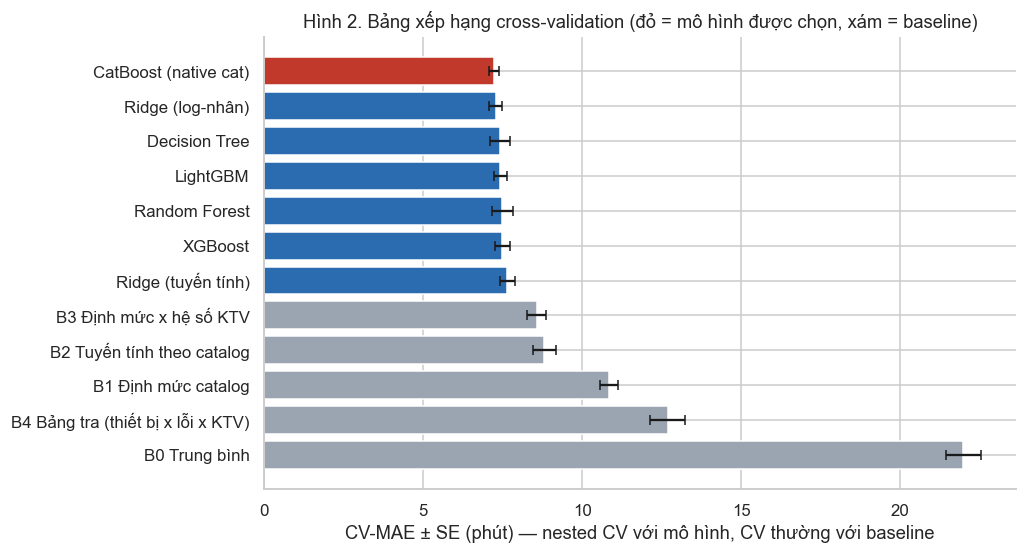

In [13]:
cv_df = pd.DataFrame(cv_rows.values())
models_df = cv_df[cv_df["kind"] == "model"].sort_values("cv_mae").reset_index(drop=True)
best_name = models_df.loc[0, "name"]
best_row = models_df.loc[0]
tie_set = models_df[models_df["cv_mae"] <= best_row["cv_mae"] + best_row["cv_se"]]["name"].tolist()
prim = cv_rows[PRIMARY_BASELINE]
gain_cv = (1 - best_row["cv_mae"] / prim["cv_mae"]) * 100
best_spec = CANDIDATES[best_name]
best_pipe, best_params, _ = deploy[best_name]

lb = cv_df.sort_values("cv_mae").reset_index(drop=True)
lb.insert(0, "hạng", lb.index + 1)
display(lb[["hạng", "name", "kind", "cv_mae", "cv_std", "cv_se", "cv_rmse", "cv_r2"]].round(3))

print(f"MÔ HÌNH ĐƯỢC CHỌN: {best_name} | nested CV-MAE = {best_row['cv_mae']:.3f} ± {best_row['cv_se']:.3f} (SE)")
print(f"Tham số triển khai: {cv_rows[best_name]['best_params']}")
cov_mask = twin_covered_mask(train_df, ISSUE_COL)
ae_oof = np.abs(nested[best_name].oof_pred - y_tr)
floor_ratio = ae_oof[cov_mask].mean() / noise["noise_mae_floor"]
print(f"So với trần nhiễu (CÙNG tập {cov_mask.sum()} phiếu có song sinh): MAE out-of-fold của mô hình = {ae_oof[cov_mask].mean():.2f} | "
      f"trần ≈ {noise['noise_mae_floor']:.2f} | tỉ lệ = {floor_ratio:.2f} (≈1 là đã chạm trần; MAE trên toàn bộ phiếu là {ae_oof.mean():.2f})")
print(f"Nhóm hòa thống kê (trong 1 SE): {tie_set}")
print(f"So với baseline mạnh nhất theo CV ({PRIMARY_BASELINE}, {prim['cv_mae']:.3f}): {'giảm' if gain_cv >= 0 else 'TĂNG'} {abs(gain_cv):.1f}% CV-MAE")
if best_row["cv_mae"] > prim["cv_mae"] - prim["cv_se"]:
    print("CẢNH BÁO: mô hình tốt nhất KHÔNG hơn baseline mạnh nhất quá 1 SE. Hãy nói thẳng điều này: ML chưa tạo giá trị "
          "vượt trội so với mô hình nhân đơn giản trên dữ liệu hiện tại.")
if len(tie_set) > 1:
    print("LƯU Ý: nhiều mô hình hòa thống kê; báo cáo 'được chọn theo CV-MAE nhỏ nhất', KHÔNG nói 'vượt trội'.")

fig, ax = plt.subplots(figsize=(9.5, 5.2))
order = lb.sort_values("cv_mae", ascending=False)
colors = [BEST_COLOR if n == best_name else (BASE_COLOR if k == "baseline" else MODEL_COLOR) for n, k in zip(order["name"], order["kind"])]
ax.barh(order["name"], order["cv_mae"], xerr=order["cv_se"], color=colors, capsize=3)
ax.set(xlabel="CV-MAE ± SE (phút) — nested CV với mô hình, CV thường với baseline", title="Hình 2. Bảng xếp hạng cross-validation (đỏ = mô hình được chọn, xám = baseline)")
plt.tight_layout(); savefig(fig, "02_leaderboard_cv"); plt.show()

## Bước 13. Ablation: sinh thêm dữ liệu có thật sự giúp?

Augmentation của dự án nhân bản các dòng train rồi cộng nhiễu Gauss vào nhãn: $y'=\max(15,\,y+\varepsilon)$, $\varepsilon\sim\mathcal N(0,3.5^2)$. Bản sao giữ nguyên $\mathbf x$ và chỉ nhiễu hóa $y$ nên **không tạo thông tin mới** về quan hệ $\mathbf x\to y$; nó có thể chỉ làm mô hình "tin" hơn vào các điểm đã có. Thay vì giả định, ta **kiểm chứng**.

Thiết kế: lặp nhiều lần chia **bên trong tập train** (không đụng test), huấn luyện mô hình đã chọn với và không có augmentation (augmentation chỉ áp dụng cho phần train con; phần kiểm định luôn là phiếu thật), so MAE ghép cặp bằng Wilcoxon. **Quy tắc quyết định:** chỉ coi augmentation là có lợi khi MAE giảm hơn một độ lệch chuẩn **và** $p<0.05$.

In [14]:
def eval_split(seed: int, augment: bool) -> float:
    gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=seed)
    a, b = next(gss.split(train_df, groups=train_df[GROUP_COL]))
    sub_tr, sub_va = train_df.iloc[a], train_df.iloc[b]
    if augment:
        sub_tr = augment_repair_dataset(sub_tr, int(len(sub_tr) * AUGMENT_FACTOR), seed)
    pipe = build_pipeline(best_spec).set_params(**best_params)
    pipe.fit(sub_tr[FEATURE_COLS], sub_tr[TARGET_COL].to_numpy(float))
    return float(np.mean(np.abs(pipe.predict(sub_va[FEATURE_COLS]) - sub_va[TARGET_COL].to_numpy(float))))

seeds = range(ABLATION_REPEATS)
mae_plain = np.array([eval_split(s, False) for s in seeds])
mae_aug = np.array([eval_split(s, True) for s in seeds])
diff = mae_plain - mae_aug                                   # > 0: augmentation GIÚP
p_abl = float(stats.wilcoxon(mae_plain, mae_aug).pvalue) if np.any(diff != 0) else 1.0
helps = (diff.mean() > mae_plain.std(ddof=1)) and (p_abl < 0.05)
display(pd.DataFrame({"MAE trung bình": [mae_plain.mean(), mae_aug.mean()], "độ lệch chuẩn qua các lần chia": [mae_plain.std(ddof=1), mae_aug.std(ddof=1)]},
                     index=["chỉ phiếu thật", "phiếu thật + augmentation"]).round(3))
print(f"Chênh lệch (thật − augment) = {diff.mean():+.3f} phút | Wilcoxon p = {p_abl:.4f} | {len(seeds)} lần chia")
print("=> Augmentation CÓ lợi theo quy tắc (cần đưa vào pipeline; hiện v3 không dùng)." if helps else
      "=> Augmentation KHÔNG có lợi theo quy tắc: huấn luyện chỉ trên phiếu thật (use_augmentation = False).")

,MAE trung bình,độ lệch chuẩn qua các lần chia
chỉ phiếu thật,6.863,0.534
phiếu thật + augmentation,7.073,0.495


Chênh lệch (thật − augment) = -0.210 phút | Wilcoxon p = 0.1094 | 8 lần chia
=> Augmentation KHÔNG có lợi theo quy tắc: huấn luyện chỉ trên phiếu thật (use_augmentation = False).


## Bước 14. Đánh giá cuối cùng trên tập test (chạm một lần)

Lấy con số hiệu năng **không thiên lệch**. Mô hình đã được chọn ở Bước 12; **không được quay lại đổi mô hình theo điểm test**, nếu không test trở thành tập validation thứ hai.

Dự đoán đi qua cùng sàn `MIN_PREDICTED_MINUTES` như khi chạy thật. Với mỗi mô hình còn tính khoảng tin cậy bootstrap 95% của MAE.

**Kiểm định ghép cặp.** Hai MAE khác nhau chưa đủ kết luận; cần biết chênh lệch có vượt nhiễu lấy mẫu không. Trên **cùng các phiếu test**, đặt $d_j=|e_j^{\text{đối thủ}}|-|e_j^{\text{chọn}}|$ và dùng **Wilcoxon signed-rank** (không giả định phân phối chuẩn). Vì so với $m$ đối thủ, ngưỡng được hiệu chỉnh **Bonferroni**: $\alpha'=0.05/m$.

,name,loại,MAE,MAE 95% CI,RMSE,R2,P90_abs_err,within_5min_pct,bias
0,CatBoost (native cat),mô hình,7.143,6.27 – 8.11,9.975,0.883,16.046,45.370,-1.394
1,Ridge (log-nhân),mô hình,7.289,6.35 – 8.28,10.261,0.876,16.445,43.981,-0.929
2,XGBoost,mô hình,7.351,6.37 – 8.45,10.826,0.862,17.831,47.222,-0.992
3,LightGBM,mô hình,7.446,6.48 – 8.56,10.738,0.864,17.280,46.296,-1.115
4,Ridge (tuyến tính),mô hình,7.571,6.65 – 8.61,10.660,0.866,16.050,45.370,-0.431
5,B2 Tuyến tính theo catalog,baseline,7.827,6.82 – 8.89,11.011,0.857,16.570,44.444,-0.492
6,B3 Định mức x hệ số KTV,baseline,7.844,6.82 – 8.90,11.119,0.855,18.235,45.833,1.110
7,Random Forest,mô hình,7.934,6.90 – 9.02,11.244,0.851,18.133,47.222,-0.076
8,Decision Tree,mô hình,8.484,7.23 – 9.97,13.487,0.786,17.560,45.833,-0.314
9,B1 Định mức catalog,baseline,9.898,8.76 – 11.14,13.608,0.782,20.500,40.278,4.991


Mô hình chọn (CatBoost (native cat)): hạng 1/12 trên test | MAE = 7.14 (CI 95%: 6.27–8.11) | CV-MAE = 7.24
So với baseline mạnh nhất theo CV (B3 Định mức x hệ số KTV, MAE test 7.84): giảm 8.9% | chênh lệch MAE ghép cặp = 0.70 phút, CI 95% [-0.19, 1.60]


,so với,MAE đối thủ − MAE chọn,% phiếu mô hình chọn thắng,p (Wilcoxon),kết luận (Bonferroni)
0,B0 Trung bình,14.7219,83.3333,0.0000,tốt hơn có ý nghĩa
1,B4 Bảng tra (thiết bị x lỗi x KTV),4.5524,64.3519,0.0000,tốt hơn có ý nghĩa
2,B1 Định mức catalog,2.7553,66.2037,0.0000,tốt hơn có ý nghĩa
3,Decision Tree,1.3407,56.9444,0.0034,tốt hơn có ý nghĩa
4,Random Forest,0.7916,53.2407,0.0484,hòa thống kê
5,B3 Định mức x hệ số KTV,0.7010,57.8704,0.0466,hòa thống kê
6,B2 Tuyến tính theo catalog,0.6847,56.4815,0.0237,hòa thống kê
7,Ridge (tuyến tính),0.4286,53.7037,0.1830,hòa thống kê
8,LightGBM,0.3034,54.1667,0.2117,hòa thống kê
9,XGBoost,0.2078,44.9074,0.3229,hòa thống kê


Ngưỡng Bonferroni: alpha' = 0.05/11 = 0.0045


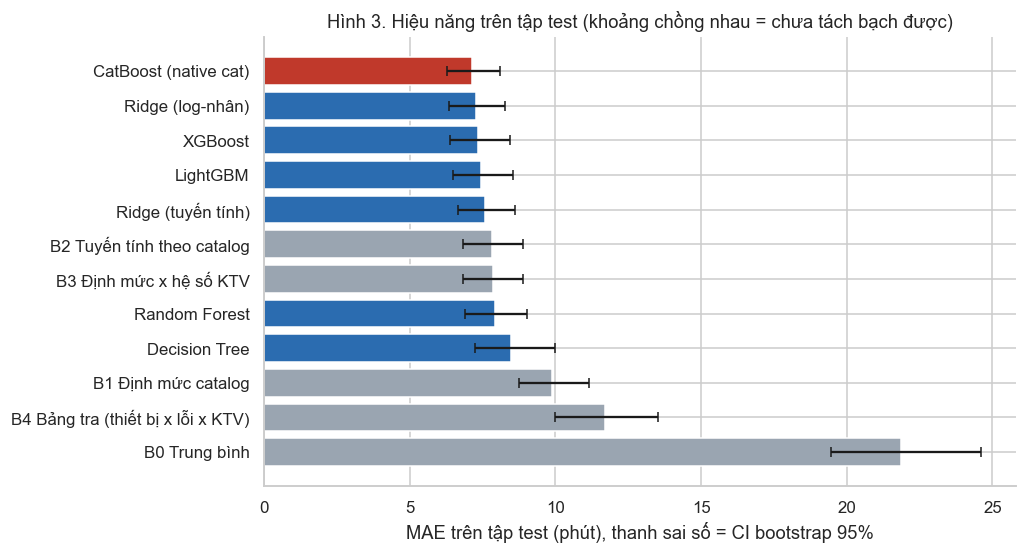

In [15]:
floor = lambda p: np.maximum(np.asarray(p, float), MIN_PREDICTED_MINUTES)
test_pred = {n: floor(deploy[n][0].predict(test_df[FEATURE_COLS])) for n in CANDIDATES}
test_pred.update({n: floor(p) for n, p in baseline_predictions(train_df, test_df, TARGET_COL, ISSUE_COL).items()})

rows = []
for n, p in test_pred.items():
    ae = np.abs(p - y_te); lo, hi = bootstrap_mae_ci(ae)
    rows.append({"name": n, "loại": "baseline" if n in BASELINE_NAMES else "mô hình", **regression_report(y_te, p), "CI_lo": lo, "CI_hi": hi})
test_res = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(test_res.assign(**{"MAE 95% CI": test_res.apply(lambda r: f"{r.CI_lo:.2f} – {r.CI_hi:.2f}", axis=1)})
        [["name", "loại", "MAE", "MAE 95% CI", "RMSE", "R2", "P90_abs_err", "within_5min_pct", "bias"]].round(3))

bt = test_res[test_res["name"] == best_name].iloc[0]
pt = test_res[test_res["name"] == PRIMARY_BASELINE].iloc[0]
print(f"Mô hình chọn ({best_name}): hạng {int(test_res.index[test_res['name']==best_name][0]) + 1}/{len(test_res)} trên test | "
      f"MAE = {bt.MAE:.2f} (CI 95%: {bt.CI_lo:.2f}–{bt.CI_hi:.2f}) | CV-MAE = {best_row['cv_mae']:.2f}")
d_ci = bootstrap_mean_ci(np.abs(test_pred[PRIMARY_BASELINE] - y_te) - np.abs(test_pred[best_name] - y_te))
print(f"So với baseline mạnh nhất theo CV ({PRIMARY_BASELINE}, MAE test {pt.MAE:.2f}): {'giảm' if bt.MAE <= pt.MAE else 'TĂNG'} {abs(1 - bt.MAE / pt.MAE) * 100:.1f}% | "
      f"chênh lệch MAE ghép cặp = {pt.MAE - bt.MAE:.2f} phút, CI 95% [{d_ci[0]:.2f}, {d_ci[1]:.2f}]")
if abs(bt.MAE - best_row["cv_mae"]) > 2 * best_row["cv_se"]:
    print(f"LƯU Ý: MAE test lệch CV-MAE hơn 2 SE; hãy báo cả hai con số (CV {best_row['cv_mae']:.2f} và test {bt.MAE:.2f}).")

e_best = np.abs(test_pred[best_name] - y_te)
alpha_adj = 0.05 / (len(test_pred) - 1)
pair_rows = []
for n, p in test_pred.items():
    if n == best_name:
        continue
    w = paired_wilcoxon(np.abs(p - y_te), e_best)
    verdict = ("tốt hơn có ý nghĩa" if (w["p_value"] < alpha_adj and w["mean_delta"] > 0)
               else "kém hơn có ý nghĩa" if (w["p_value"] < alpha_adj and w["mean_delta"] < 0) else "hòa thống kê")
    pair_rows.append({"so với": n, "MAE đối thủ − MAE chọn": w["mean_delta"], "% phiếu mô hình chọn thắng": w["pct_best_wins"],
                      "p (Wilcoxon)": w["p_value"], "kết luận (Bonferroni)": verdict})
pairs = pd.DataFrame(pair_rows).sort_values("MAE đối thủ − MAE chọn", ascending=False)
display(pairs.round(4).reset_index(drop=True))
print(f"Ngưỡng Bonferroni: alpha' = 0.05/{len(test_pred) - 1} = {alpha_adj:.4f}")

fig, ax = plt.subplots(figsize=(9.5, 5.2))
o = test_res.sort_values("MAE", ascending=False)
cols = [BEST_COLOR if n == best_name else (BASE_COLOR if k == "baseline" else MODEL_COLOR) for n, k in zip(o["name"], o["loại"])]
ax.barh(o["name"], o["MAE"], xerr=[o["MAE"] - o["CI_lo"], o["CI_hi"] - o["MAE"]], color=cols, capsize=3)
ax.set(xlabel="MAE trên tập test (phút), thanh sai số = CI bootstrap 95%", title="Hình 3. Hiệu năng trên tập test (khoảng chồng nhau = chưa tách bạch được)")
plt.tight_layout(); savefig(fig, "03_test_results"); plt.show()

**Một con số MAE che giấu *sai ở đâu*.** Hình 4 chẩn đoán sai số của mô hình đã chọn: (a) dự đoán vs thực tế, càng sát đường chéo càng tốt; (b) phần dư vs dự đoán (phần dư $=\hat y-y$): nếu hình **phễu** (loe ra) thì sai số tăng theo độ dài ca, tức nhiễu nhân (và khoảng dự báo cố định sẽ không công bằng); nếu **cong** thì mô hình bỏ sót cấu trúc; (c) phân phối phần dư nên đối xứng quanh 0; (d) MAE theo KTV: nếu một KTV sai nhiều hơn hẳn thì mô hình không công bằng với người đó.

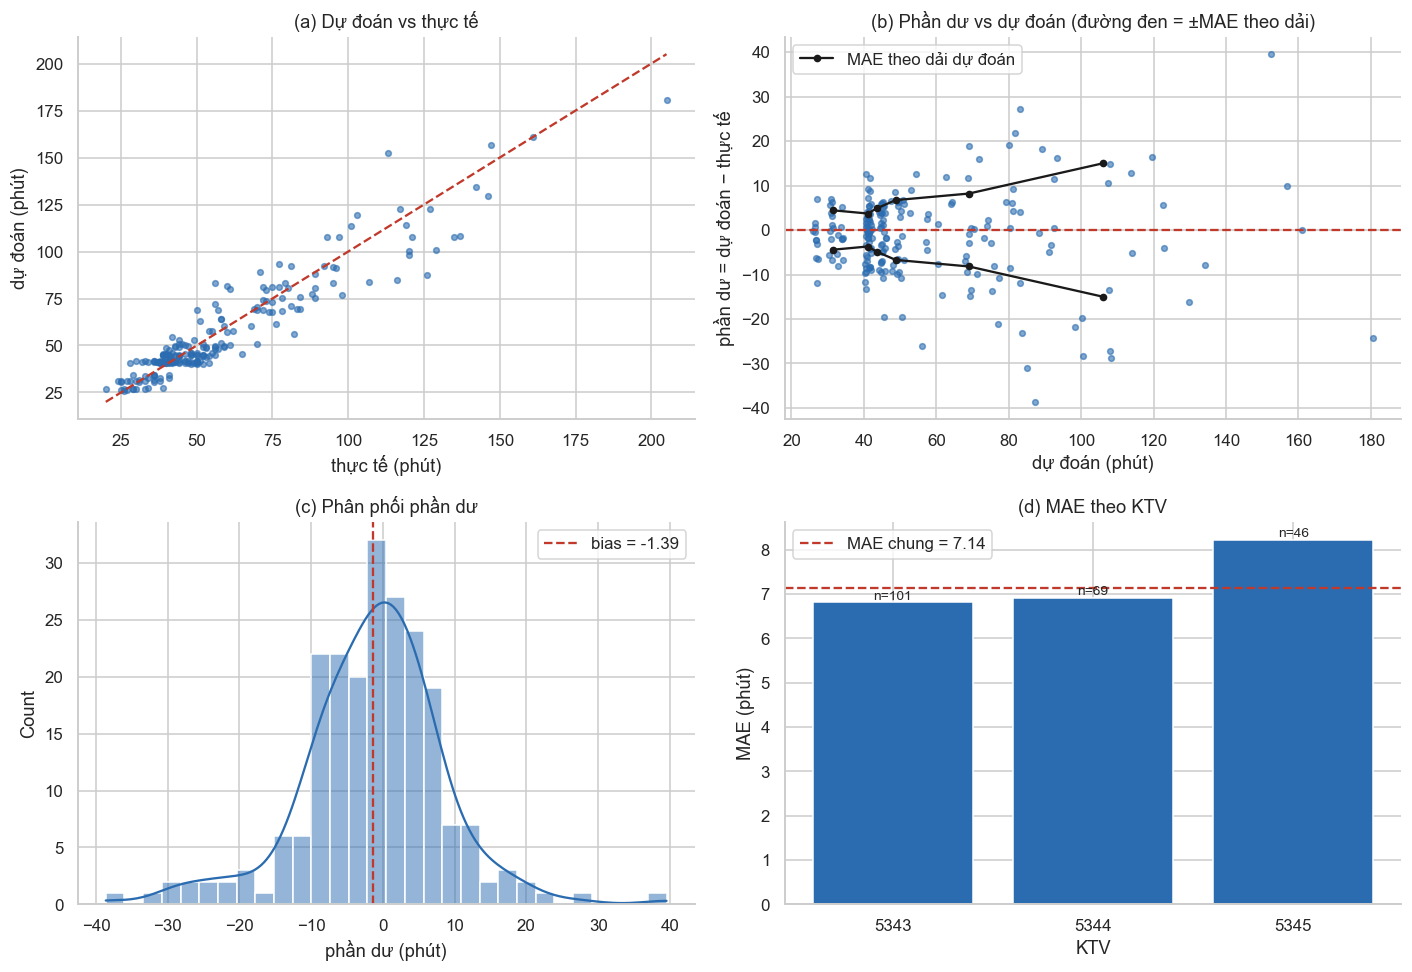

MAE/RMSE = 0.72 (≈0.80 nếu sai số Gauss; thấp hơn nhiều = có vài ca lệch rất lớn)
MAE theo ba dải dự đoán (thấp → cao): [4.07, 5.77, 11.58] | tăng dần theo độ dài ca: sai số tăng cùng ca dài (nhiễu nhân)


,ticket_id,service_issue_ids_list,device_model_id,technician_id,total_services_count,thực tế,dự đoán,sai số tuyệt đối
0,12169,"1,5",1416,5343,2,113.0,152.5,39.5
1,13023,"4,6",782,5345,2,126.0,87.4,38.6
2,12139,"2,5,7",782,5343,3,116.0,85.0,31.0
3,12900,"1,5,6",789,5344,3,137.0,108.2,28.8
4,12213,"2,4,7",1444,5343,3,129.0,100.6,28.4


In [16]:
p_b = test_pred[best_name]; res = p_b - y_te
diag = test_df[[GROUP_COL, ISSUE_COL, "device_model_id", "technician_id", SERVICES_COL]].copy()
diag["thực tế"], diag["dự đoán"], diag["sai số tuyệt đối"] = y_te, p_b.round(1), np.abs(res).round(1)

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].scatter(y_te, p_b, s=14, alpha=0.6, color=MODEL_COLOR)
lim = [min(y_te.min(), p_b.min()), max(y_te.max(), p_b.max())]
ax[0, 0].plot(lim, lim, "--", c=BEST_COLOR); ax[0, 0].set(title="(a) Dự đoán vs thực tế", xlabel="thực tế (phút)", ylabel="dự đoán (phút)")
ax[0, 1].scatter(p_b, res, s=14, alpha=0.6, color=MODEL_COLOR); ax[0, 1].axhline(0, c=BEST_COLOR, ls="--")
bins = pd.qcut(p_b, 6, duplicates="drop"); band = pd.DataFrame({"p": p_b, "r": res, "b": bins}).groupby("b", observed=True).agg(p=("p", "mean"), s=("r", lambda v: np.mean(np.abs(v))))
ax[0, 1].plot(band["p"], band["s"], "k-o", ms=4, label="MAE theo dải dự đoán"); ax[0, 1].plot(band["p"], -band["s"], "k-o", ms=4)
ax[0, 1].set(title="(b) Phần dư vs dự đoán (đường đen = ±MAE theo dải)", xlabel="dự đoán (phút)", ylabel="phần dư = dự đoán − thực tế"); ax[0, 1].legend()
sns.histplot(res, bins=30, kde=True, ax=ax[1, 0], color=MODEL_COLOR); ax[1, 0].axvline(res.mean(), c=BEST_COLOR, ls="--", label=f"bias = {res.mean():+.2f}")
ax[1, 0].set(title="(c) Phân phối phần dư", xlabel="phần dư (phút)"); ax[1, 0].legend()
per_t = diag.groupby("technician_id")["sai số tuyệt đối"].agg(["mean", "count"])
ax[1, 1].bar(per_t.index.astype(str), per_t["mean"], color=MODEL_COLOR)
ax[1, 1].axhline(np.abs(res).mean(), c=BEST_COLOR, ls="--", label=f"MAE chung = {np.abs(res).mean():.2f}")
for i, (m_, c_) in enumerate(zip(per_t["mean"], per_t["count"])): ax[1, 1].text(i, m_, f"n={c_}", ha="center", va="bottom", fontsize=9)
ax[1, 1].set(title="(d) MAE theo KTV", xlabel="KTV", ylabel="MAE (phút)"); ax[1, 1].legend()
plt.tight_layout(); savefig(fig, "04_error_diagnostics"); plt.show()

print(f"MAE/RMSE = {bt.MAE / bt.RMSE:.2f} (≈0.80 nếu sai số Gauss; thấp hơn nhiều = có vài ca lệch rất lớn)")
sd_spread = diag.groupby(pd.qcut(p_b, 3, duplicates='drop'), observed=True)["sai số tuyệt đối"].mean()
inc = bool(np.all(np.diff(sd_spread.to_numpy()) > 0))
print("MAE theo ba dải dự đoán (thấp → cao):", sd_spread.round(2).tolist(),
      "| tăng dần theo độ dài ca: sai số tăng cùng ca dài (nhiễu nhân)" if inc else "| KHÔNG tăng đều theo độ dài ca: đọc kèm Hình 4b, không kết luận vội về nhiễu nhân")
display(diag.nlargest(5, "sai số tuyệt đối").reset_index(drop=True))

## Bước 15. Đường cong học

Trả lời "**có nên thu thập thêm dữ liệu không?**" bằng số liệu: huấn luyện mô hình đã chọn với tỉ lệ dữ liệu tăng dần (20% đến 100% phần train của mỗi fold) và đo MAE trên train và trên fold kiểm định.

$$\text{Sai số kiểm định}\approx\underbrace{\text{độ chệch}^2}_{\text{mô hình quá đơn giản}}+\underbrace{\text{phương sai}}_{\text{quá ít dữ liệu}}+\underbrace{\sigma^2}_{\text{nhiễu không giảm được}}$$

* Hai đường **hội tụ** và đường kiểm định đã phẳng: mô hình đã khai thác hết thông tin trong đặc trưng; muốn tốt hơn phải thêm đặc trưng hoặc giảm nhiễu nhãn.
* Khoảng cách lớn và đường kiểm định còn đi xuống: thêm dữ liệu thật sẽ giúp.

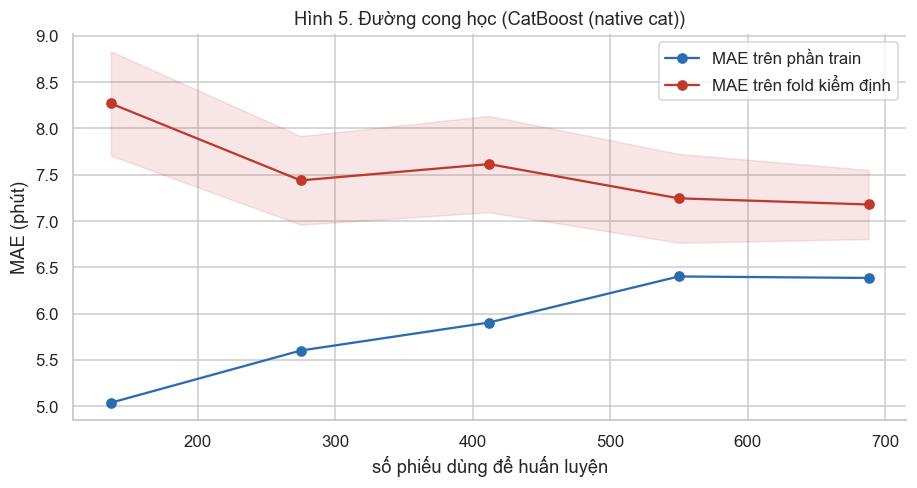

Tại n tối đa: MAE kiểm định − train = 0.79 phút | MAE kiểm định còn giảm 0.07 phút ở bước cuối
=> Đường kiểm định đã phẳng: thêm dữ liệu cùng loại ít giúp; cải thiện cần đặc trưng mới hoặc nhãn ít nhiễu hơn.


In [17]:
sizes, tr_sc, va_sc = learning_curve(clone(best_pipe), train_df[FEATURE_COLS], y_tr, cv=outer_folds,
                                     train_sizes=np.linspace(0.2, 1.0, 5), scoring="neg_mean_absolute_error", n_jobs=1)
tr_m, va_m = -tr_sc.mean(1), -va_sc.mean(1)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(sizes, tr_m, "o-", c=MODEL_COLOR, label="MAE trên phần train")
ax.plot(sizes, va_m, "o-", c=BEST_COLOR, label="MAE trên fold kiểm định")
ax.fill_between(sizes, -va_sc.mean(1) - va_sc.std(1), -va_sc.mean(1) + va_sc.std(1), color=BEST_COLOR, alpha=0.12)
ax.set(xlabel="số phiếu dùng để huấn luyện", ylabel="MAE (phút)", title=f"Hình 5. Đường cong học ({best_name})"); ax.legend()
plt.tight_layout(); savefig(fig, "05_learning_curve"); plt.show()
gap, slope_last = va_m[-1] - tr_m[-1], va_m[-2] - va_m[-1]
print(f"Tại n tối đa: MAE kiểm định − train = {gap:.2f} phút | MAE kiểm định còn giảm {slope_last:.2f} phút ở bước cuối")
print("=> Đường kiểm định còn đi xuống: thêm dữ liệu thật có khả năng cải thiện." if slope_last > 0.1 else
      "=> Đường kiểm định đã phẳng: thêm dữ liệu cùng loại ít giúp; cải thiện cần đặc trưng mới hoặc nhãn ít nhiễu hơn.")

## Bước 16. Giải thích mô hình

Mô hình dựa vào cái gì để dự đoán, và có hợp lý nghiệp vụ không?

**16.1. Permutation importance** trên test: xáo ngẫu nhiên các giá trị của **một đặc trưng gốc** (cột thô, nên không bị one-hot chia nhỏ) và đo MAE tăng bao nhiêu, lặp 20 lần.
$$\text{PI}_g=\mathbb E_\pi\big[\text{MAE}(\mathbf X^{\pi(g)})\big]-\text{MAE}(\mathbf X)$$
Đặc trưng tương quan với nhau (định mức và số dịch vụ) chia sẻ mức quan trọng nên từng giá trị nên đọc như thứ tự, không phải con số tuyệt đối.

**16.2. "What-if" theo KTV:** giữ nguyên phiếu test, chỉ đổi KTV, lấy trung bình dự đoán. Chỉ số tốc độ = trung bình dự đoán của KTV / trung bình các KTV. Đối chiếu với hai ước lượng độc lập: $\bar\rho$ thô quan sát được (Bước 6) và **hệ số đã hiệu chỉnh độ khó ca** (ANCOVA). Nếu mô hình học đúng thì ba cột phải gần nhau; **hệ số hiệu chỉnh mới là chuẩn đối chiếu đáng tin hơn $\bar\rho$ thô** vì nó đã loại ảnh hưởng của việc phân ca không ngẫu nhiên.

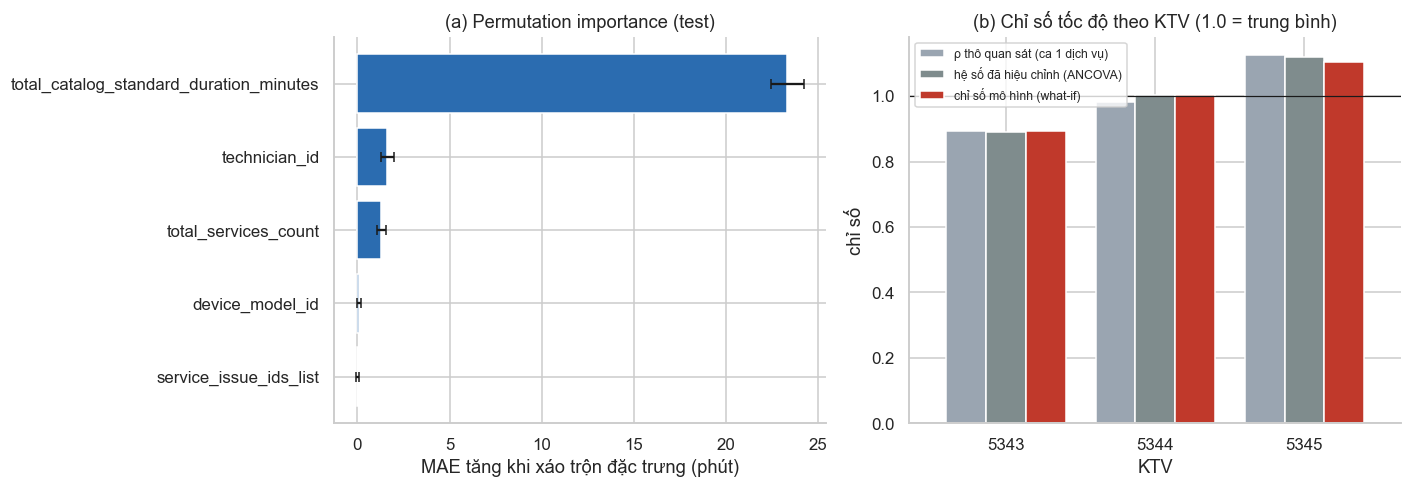

,ρ thô quan sát (ca 1 dịch vụ),hệ số đã hiệu chỉnh (ANCOVA),chỉ số mô hình (what-if)
5343,0.892,0.891,0.893
5344,0.983,1.003,1.002
5345,1.125,1.118,1.105


Cùng một phiếu, chênh lệch dự đoán giữa KTV nhanh nhất và chậm nhất: 12.4 phút (trung bình 58.3). Đó là cơ sở để hệ thống gợi ý KTV xong sớm nhất.


In [18]:
pi = permutation_importance(best_pipe, test_df[FEATURE_COLS], y_te, scoring="neg_mean_absolute_error",
                            n_repeats=20, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"đặc trưng": FEATURE_COLS, "MAE tăng (phút)": pi.importances_mean, "std": pi.importances_std}).sort_values("MAE tăng (phút)")

techs = best_pipe.named_steps["fe"].categories_["technician_id"]
wi = {}
for t in techs:
    tmp = test_df[FEATURE_COLS].copy(); tmp["technician_id"] = t
    wi[t] = float(np.mean(floor(best_pipe.predict(tmp))))
model_idx = pd.Series(wi) / np.mean(list(wi.values()))
raw_norm = raw_idx / raw_idx.mean()
cmp_df = pd.DataFrame({"ρ thô quan sát (ca 1 dịch vụ)": raw_norm.round(3), "hệ số đã hiệu chỉnh (ANCOVA)": pd.Series(anc["factors"]).round(3),
                       "chỉ số mô hình (what-if)": model_idx.round(3)})

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].barh(imp["đặc trưng"], imp["MAE tăng (phút)"], xerr=imp["std"], color=MODEL_COLOR, capsize=3)
ax[0].set(title="(a) Permutation importance (test)", xlabel="MAE tăng khi xáo trộn đặc trưng (phút)")
cmp_df.plot.bar(ax=ax[1], width=0.8, color=[BASE_COLOR, "#7f8c8d", BEST_COLOR]); ax[1].axhline(1, c="k", lw=0.8)
ax[1].set(title="(b) Chỉ số tốc độ theo KTV (1.0 = trung bình)", xlabel="KTV", ylabel="chỉ số"); ax[1].legend(fontsize=8)
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=0)
plt.tight_layout(); savefig(fig, "06_interpretation"); plt.show()
display(cmp_df)
spread_min = max(wi.values()) - min(wi.values())
print(f"Cùng một phiếu, chênh lệch dự đoán giữa KTV nhanh nhất và chậm nhất: {spread_min:.1f} phút (trung bình {np.mean(list(wi.values())):.1f}). "
      f"Đó là cơ sở để hệ thống gợi ý KTV xong sớm nhất.")

## Bước 17. Khoảng dự báo 90%

Một con số "47 phút" không nói lên độ chắc chắn; cần cả khoảng. Dùng **split conformal** trên phần dư **out-of-fold của nested CV** (mỗi mẫu được dự đoán bởi mô hình chưa thấy nó *và* chưa tham gia chọn tham số của nó), có hiệu chỉnh cỡ mẫu hữu hạn:

$$\hat q=\text{Quantile}_{\lceil(n+1)(1-\alpha)\rceil/n}\big(\{s_i\}\big)$$

Hai kiểu độ đo bất tương thích $s_i$:

* **absolute:** $s_i=|y_i-\hat y_i|$, khoảng $\hat y\pm\hat q$ (độ rộng cố định).
* **relative:** $s_i=|y_i-\hat y_i|/\hat y_i$, khoảng $\hat y(1\pm\hat q)$ (độ rộng tỉ lệ với dự đoán).

**Chọn kiểu chỉ bằng dữ liệu hiệu chuẩn (không nhìn test):** nếu $|r_i|$ tăng theo $\hat y_i$ (Spearman $\rho>0.15$, $p<0.01$) thì nhiễu là nhân và khoảng tỉ lệ công bằng hơn: ca ngắn không bị khoảng quá rộng, ca dài không bị quá hẹp. Cả hai kiểu đều bảo đảm độ phủ **trung bình** ≥ 90% (với dữ liệu hoán đổi được), khác nhau ở độ phủ **theo từng nhóm**.

Spearman(|phần dư|, dự đoán) trên OOF: rho = 0.40, p = 4.4e-34 => chọn kiểu 'relative' | q_abs = 15.58 phút | q_rel = 0.255 (±25.5%)


,độ phủ chung,độ rộng TB (phút),phủ ca ngắn,phủ ca vừa,phủ ca dài
absolute,0.894,31.156,1.000,0.972,0.708
relative,0.912,28.869,0.931,0.958,0.847
(mục tiêu),0.900,NaN,NaN,NaN,NaN


KIỂU ĐƯỢC CHỌN 'relative': độ phủ thực trên test = 91.2% (mục tiêu 90%; sai số lấy mẫu ≈ ±1.9 điểm %) | độ rộng trung bình = 28.9 phút
Độ phủ theo KTV: {5343: '86.1% (n=101)', 5344: '94.2% (n=69)', 5345: '97.8% (n=46)'}


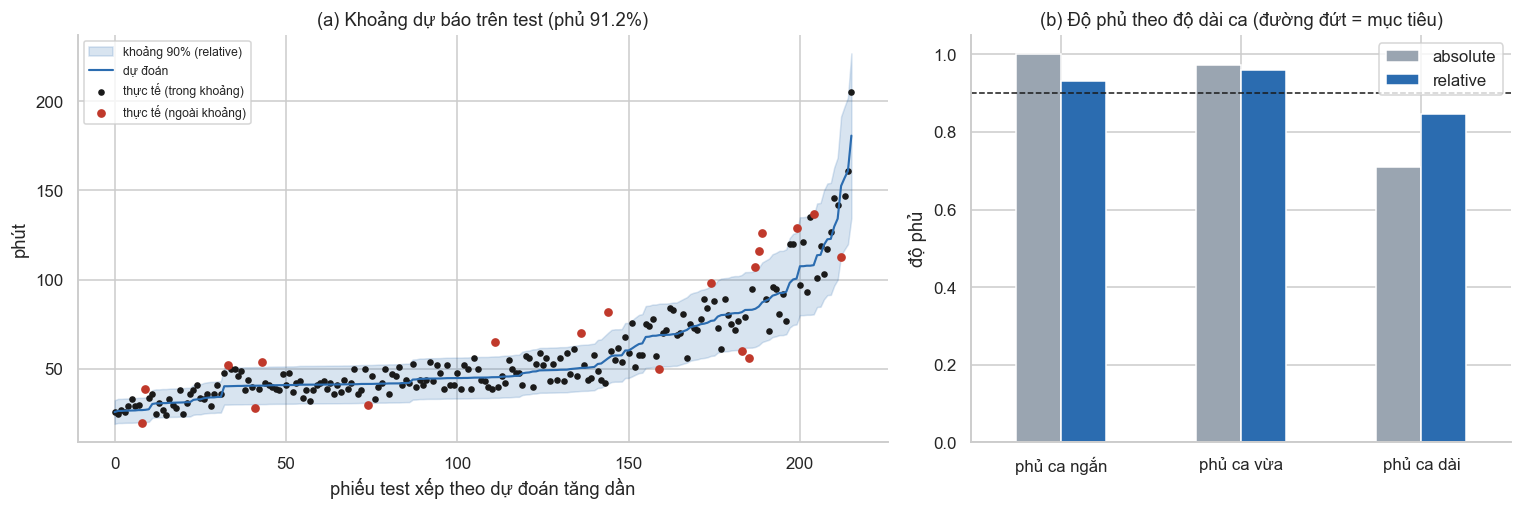

In [19]:
oof_best = nested[best_name].oof_pred
interval = calibrate_interval(y_tr, oof_best, INTERVAL_COVERAGE, MIN_PREDICTED_MINUTES)
print(f"Spearman(|phần dư|, dự đoán) trên OOF: rho = {interval['spearman_rho']:.2f}, p = {interval['spearman_p']:.1e} "
      f"=> chọn kiểu '{interval['method']}' | q_abs = {interval['q_abs']:.2f} phút | q_rel = {interval['q_rel']:.3f} (±{interval['q_rel']*100:.1f}%)")

variants = {"absolute": {**interval, "method": "absolute"}, "relative": {**interval, "method": "relative"}}
tercile = pd.qcut(p_b, 3, labels=["ca ngắn", "ca vừa", "ca dài"], duplicates="drop")
cov_tbl = {}
for k, iv in variants.items():
    lo_k, hi_k = interval_bounds(p_b, iv, MIN_PREDICTED_MINUTES)
    ins = (y_te >= lo_k) & (y_te <= hi_k)
    cov_tbl[k] = {"độ phủ chung": ins.mean(), "độ rộng TB (phút)": (hi_k - lo_k).mean(),
                  **{f"phủ {t}": ins[tercile == t].mean() for t in tercile.categories}}
cov_df = pd.DataFrame(cov_tbl).T
cov_df.loc["(mục tiêu)", "độ phủ chung"] = INTERVAL_COVERAGE
display(cov_df.round(3))

lo_b, hi_b = interval_bounds(p_b, interval, MIN_PREDICTED_MINUTES)
inside = (y_te >= lo_b) & (y_te <= hi_b)
coverage = float(inside.mean())
n_te = len(y_te); se_cov = np.sqrt(coverage * (1 - coverage) / n_te)
cov_by_tech = pd.Series(inside).groupby(test_df["technician_id"].to_numpy()).agg(["mean", "count"]).round(3)
print(f"KIỂU ĐƯỢC CHỌN '{interval['method']}': độ phủ thực trên test = {coverage:.1%} (mục tiêu {INTERVAL_COVERAGE:.0%}; sai số lấy mẫu ≈ ±{se_cov*100:.1f} điểm %) "
      f"| độ rộng trung bình = {(hi_b - lo_b).mean():.1f} phút")
print("Độ phủ theo KTV:", {int(i): f"{r['mean']:.1%} (n={int(r['count'])})" for i, r in cov_by_tech.iterrows()})

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
o = np.argsort(p_b); x = np.arange(len(o))
ax[0].fill_between(x, lo_b[o], hi_b[o], color=MODEL_COLOR, alpha=0.18, label=f"khoảng {INTERVAL_COVERAGE:.0%} ({interval['method']})")
ax[0].plot(x, p_b[o], c=MODEL_COLOR, lw=1.4, label="dự đoán")
ax[0].scatter(x[inside[o]], y_te[o][inside[o]], s=11, c="k", label="thực tế (trong khoảng)")
ax[0].scatter(x[~inside[o]], y_te[o][~inside[o]], s=22, c=BEST_COLOR, label="thực tế (ngoài khoảng)")
ax[0].set(title=f"(a) Khoảng dự báo trên test (phủ {coverage:.1%})", xlabel="phiếu test xếp theo dự đoán tăng dần", ylabel="phút"); ax[0].legend(fontsize=8)
cov_df.loc[["absolute", "relative"], [c for c in cov_df.columns if c.startswith("phủ ")]].T.plot.bar(ax=ax[1], color=[BASE_COLOR, MODEL_COLOR], rot=0)
ax[1].axhline(INTERVAL_COVERAGE, c="k", ls="--", lw=1); ax[1].set(title="(b) Độ phủ theo độ dài ca (đường đứt = mục tiêu)", ylim=(0, 1.05), ylabel="độ phủ")
plt.tight_layout(); savefig(fig, "07_prediction_interval"); plt.show()

**Ý nghĩa đúng của "độ tin cậy".** Đây là **mức phủ thực nghiệm** của khoảng (thay cho việc gán $R^2$ vào cột `confidence`). Với dữ liệu hoán đổi được, xác suất khoảng chứa giá trị thật không nhỏ hơn 90% *tính trung bình trên các phiếu*, **không** phải xác suất đúng của từng phiếu riêng lẻ. Độ phủ trên vài trăm phiếu test có sai số lấy mẫu vài điểm phần trăm nên "90,4%" nên đọc là "khoảng 90%". Lời bảo đảm cần giả định dữ liệu mới giống dữ liệu cũ; nếu phân phối trôi (drift) thì độ phủ có thể giảm, vì vậy cần giám sát (`scripts/07_monitor_feedback.py`).

## Bước 18. Đóng gói bundle để đưa vào hệ thống

1. **Refit mô hình đã chọn (đúng tham số) trên toàn bộ dữ liệu sạch** (train + test): sau khi đã chọn và đánh giá xong, dùng thêm dữ liệu test để học là hợp lệ. Hiệu năng báo cáo vẫn là con số của Bước 14 (mô hình chỉ học trên train).
2. **Lập metadata** (tên và phiên bản mô hình, cờ dữ liệu mô phỏng, tham số, chỉ số test + CI, kiểu và độ rộng khoảng dự báo, kết quả chọn mô hình, trần nhiễu, phiên bản thư viện...).
3. **Lưu MỘT file** chứa bộ mã hóa, mô hình và metadata (tránh lỗi "bộ mã hóa một nơi, mô hình một nẻo"); ghi `metrics.json` và các bảng CSV vào `reports/`.
4. **Kiểm tra nạp lại:** nạp bundle từ đĩa, dự đoán 5 phiếu, `assert` trùng với mô hình trong bộ nhớ.

In [20]:
final_pipe = fit_final_pipeline(best_spec, best_params, df)
VERSION = new_version_tag()
half_widths = (hi_b - lo_b) / 2
best_tm = {k: float(bt[k]) for k in ("MAE", "RMSE", "R2", "P90_abs_err", "within_5min_pct", "bias")}
prim_tm = {k: float(pt[k]) for k in ("MAE", "RMSE", "R2", "P90_abs_err", "within_5min_pct", "bias")}
metadata = {
    "model_name": best_name, "model_version": VERSION, "trained_at": pd.Timestamp.now().isoformat(timespec="seconds"),
    "synthetic_data": SYNTHETIC_DATA, "use_augmentation": False,
    "best_params": {k: (v if isinstance(v, (int, float, str)) or v is None else str(v)) for k, v in cv_rows[best_name]["best_params"].items()},
    "n_train_rows_final": int(len(df)), "n_test_rows_eval": int(len(test_df)),
    "test_metrics": best_tm, "test_mae_ci95": [float(bt.CI_lo), float(bt.CI_hi)],
    "baseline_primary_name": PRIMARY_BASELINE, "baseline_primary_test_metrics": prim_tm,
    "selection": {"rule": "CV-MAE nhỏ nhất theo nested CV", "cv_mae": float(best_row["cv_mae"]), "cv_se": float(best_row["cv_se"]),
                  "statistical_tie_set": tie_set, "primary_baseline_cv_mae": float(prim["cv_mae"]), "outer_folds": CV_FOLDS, "inner_folds": INNER_CV_FOLDS},
    "noise_floor": {k: float(v) for k, v in noise.items()},
    "interval_coverage": INTERVAL_COVERAGE, "interval_method": interval["method"],
    "interval_q_abs": float(interval["q_abs"]), "interval_q_rel": float(interval["q_rel"]),
    "interval_halfwidth_minutes": float(np.median(half_widths)), "interval_test_coverage": coverage,
    "split_mode": SPLIT_MODE, "cleaning": clean_report, "features": list(final_pipe.named_steps["fe"].feature_names_),
    "technician_ids": [int(t) for t in final_pipe.named_steps["fe"].categories_["technician_id"]],
    "versions": base_versions(),
}
package_bundle(BUNDLE_PATH, final_pipe, metadata)
(REPORTS_DIR / "metrics.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
lb.drop(columns=["fold_maes"]).to_csv(REPORTS_DIR / "cv_leaderboard.csv", index=False)
test_res.to_csv(REPORTS_DIR / "test_comparison.csv", index=False)
pairs.to_csv(REPORTS_DIR / "paired_tests.csv", index=False)
diag.nlargest(15, "sai số tuyệt đối").to_csv(REPORTS_DIR / "top_errors.csv", index=False)
cmp_df.to_csv(REPORTS_DIR / "technician_effect.csv")

check = reload_check(BUNDLE_PATH, final_pipe, df)
print(f"Đã lưu bundle: {BUNDLE_PATH}  | phiên bản {VERSION}")
display(check)
print("Lưu ý: mô hình đóng gói đã học cả các phiếu này, nên bảng chỉ để kiểm tra nạp lại, KHÔNG dùng để đánh giá.")

Đã lưu bundle: D:\Class\DOAN\CNPM\apple-repair-service\apple-repair-service\ml\models\v2\repair_duration_bundle.joblib  | phiên bản v3-20261108


,thực_tế,predicted_minutes,lower_minutes,upper_minutes
239,49.0,45.8,34.1,57.4
1012,95.0,90.5,67.4,113.6
725,64.0,48.4,36.1,60.8
486,47.0,44.5,33.1,55.8
561,55.0,46.8,34.9,58.8


Lưu ý: mô hình đóng gói đã học cả các phiếu này, nên bảng chỉ để kiểm tra nạp lại, KHÔNG dùng để đánh giá.


## Bước 19. Tổng kết

Ô dưới **tự tổng hợp kết luận từ kết quả vừa chạy** (không điền tay con số), kèm các cảnh báo trung thực nên nói chủ động với hội đồng.

In [21]:
sep = "=" * 80
print(sep); print("TỔNG KẾT"); print(sep)
print(f"1. Dữ liệu : {len(df)} phiếu sạch ({'MÔ PHỎNG có kiểm soát' if SYNTHETIC_DATA else 'vận hành thật'}), {df['technician_id'].nunique()} KTV, "
      f"{df['device_model_id'].nunique()} đời máy; tách theo phiếu {len(train_df)}/{len(test_df)} (chế độ {SPLIT_MODE}).")
print(f"2. Tín hiệu KTV: ANCOVA hiệu chỉnh độ khó ca F={anc['F']:.1f}, p={anc['p_value']:.1e}, partial eta^2={anc['partial_eta2']:.2f}; "
      f"hệ số tốc độ đã hiệu chỉnh {{{', '.join(f'{k}: {v:.2f}' for k, v in anc['factors'].items())}}}.")
print(f"3. Cuộc thi: {len(CANDIDATES)} mô hình + {len(BASELINE_NAMES)} baseline, {CV_FOLDS}-fold theo phiếu, tinh chỉnh bằng nested CV ({INNER_CV_FOLDS} fold trong). "
      f"Chọn theo CV-MAE nhỏ nhất: {best_name} ({best_row['cv_mae']:.2f} ± {best_row['cv_se']:.2f}).")
print(f"4. Test ({len(test_df)} phiếu): MAE {bt.MAE:.2f} (CI 95% {bt.CI_lo:.2f}–{bt.CI_hi:.2f}), RMSE {bt.RMSE:.2f}, R2 {bt.R2:.3f}, "
      f"{bt.within_5min_pct:.0f}% ca lệch không quá 5 phút.")
print(f"5. So baseline mạnh nhất theo CV ({PRIMARY_BASELINE}): MAE test {pt.MAE:.2f} -> {bt.MAE:.2f} ({'giảm' if bt.MAE <= pt.MAE else 'TĂNG'} {abs(1 - bt.MAE / pt.MAE) * 100:.1f}%) "
      f"(CI 95% của chênh lệch ghép cặp [{d_ci[0]:.2f}, {d_ci[1]:.2f}] phút).")
print(f"6. Trần nhiễu (phiếu song sinh): MAE ≈ {noise['noise_mae_floor']:.2f}; trên cùng tập phiếu đó mô hình đạt {ae_oof[cov_mask].mean():.2f} (tỉ lệ {floor_ratio:.2f}).")
print(f"7. Khoảng dự báo {INTERVAL_COVERAGE:.0%} (kiểu {interval['method']}): độ phủ thực {coverage:.1%}, độ rộng trung bình {(hi_b - lo_b).mean():.1f} phút.")
print(f"8. Augmentation: {'có lợi' if helps else 'không có lợi -> không dùng'} (Wilcoxon p = {p_abl:.3f}).")
print(sep); print("CẢNH BÁO TRUNG THỰC (nên nói chủ động):")
if SYNTHETIC_DATA:
    print(" - Dữ liệu là MÔ PHỎNG: kết quả chứng minh quy trình đúng, chưa chứng minh hiệu năng thực địa. Khi có dữ liệu thật: đặt SYNTHETIC_DATA=False, chạy lại notebook.")
if len(tie_set) > 1:
    print(f" - {len(tie_set)} mô hình hòa thống kê trong 1 SE ({', '.join(tie_set)}): nói 'được chọn theo CV-MAE nhỏ nhất', không nói 'vượt trội'.")
if best_row["cv_mae"] > prim["cv_mae"] - prim["cv_se"]:
    print(f" - Mô hình chọn không hơn rõ rệt baseline mạnh nhất ({PRIMARY_BASELINE}); cân nhắc dùng mô hình nhân đơn giản.")
if floor_ratio < 0.8:
    print(" - Sai số của mô hình thấp hơn đáng kể trần nhiễu (cùng tập phiếu): kiểm tra rò rỉ dữ liệu hoặc dữ liệu trùng trước khi báo cáo.")
print(" - Nhãn lấy từ phiếu đã hoàn tất: lúc dự đoán sớm có thể thiếu hạng mục phát sinh về sau; cần dự đoán lại khi hạng mục thay đổi.")
print(" - Test chỉ đo khả năng dự đoán các loại phiếu đã gặp (cùng tổ hợp thiết bị/dịch vụ có thể xuất hiện ở cả train và test); chưa đo dịch vụ/đời máy hoàn toàn mới.")

TỔNG KẾT
1. Dữ liệu : 1076 phiếu sạch (MÔ PHỎNG có kiểm soát), 3 KTV, 21 đời máy; tách theo phiếu 860/216 (chế độ group).
2. Tín hiệu KTV: ANCOVA hiệu chỉnh độ khó ca F=133.5, p=5.8e-51, partial eta^2=0.24; hệ số tốc độ đã hiệu chỉnh {5343: 0.89, 5344: 1.00, 5345: 1.12}.
3. Cuộc thi: 7 mô hình + 5 baseline, 5-fold theo phiếu, tinh chỉnh bằng nested CV (3 fold trong). Chọn theo CV-MAE nhỏ nhất: CatBoost (native cat) (7.24 ± 0.16).
4. Test (216 phiếu): MAE 7.14 (CI 95% 6.27–8.11), RMSE 9.97, R2 0.883, 45% ca lệch không quá 5 phút.
5. So baseline mạnh nhất theo CV (B3 Định mức x hệ số KTV): MAE test 7.84 -> 7.14 (giảm 8.9%) (CI 95% của chênh lệch ghép cặp [-0.19, 1.60] phút).
6. Trần nhiễu (phiếu song sinh): MAE ≈ 5.42; trên cùng tập phiếu đó mô hình đạt 5.53 (tỉ lệ 1.02).
7. Khoảng dự báo 90% (kiểu relative): độ phủ thực 91.2%, độ rộng trung bình 28.9 phút.
8. Augmentation: không có lợi -> không dùng (Wilcoxon p = 0.109).
CẢNH BÁO TRUNG THỰC (nên nói chủ động):
 - Dữ liệu là MÔ PHỎNG: kế

### Dùng kết quả vào hệ thống

1. Bundle nằm ở `models/v2/repair_duration_bundle.joblib`; `05_predict_demo.py`, `06_db_service.py` và `app.py` nạp trực tiếp, **không cần sửa code** khi đổi mô hình (tên, phiên bản, khoảng dự báo, cờ dữ liệu mô phỏng đều lấy từ metadata).
2. `scripts/03_train_evaluate.py` chạy **đúng cùng pipeline** này không có đồ thị (cùng hàm trong `src/`, cùng seed) để huấn luyện lại nhanh; kết quả trùng với notebook.
3. Sau triển khai, chạy `scripts/07_monitor_feedback.py` định kỳ: MAE thực tế > 1,5 lần MAE lúc test thì trạng thái `RETRAIN_RECOMMENDED`.
4. Khi có dữ liệu thật: xuất lại CSV (`01`), đặt `SYNTHETIC_DATA=False`, cân nhắc `SPLIT_MODE="time"`, rồi **Restart & Run All**.